# 1. Data Loading

In [1]:

# ============================================================
# Cell 1 — Environment & Data Loading
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. 本地项目路径
PROJECT_ROOT = Path(r"F:\Recommendation\RecSys-Lab")
RESULTS_ROOT = PROJECT_ROOT / "results"
OUTPUT_DIR = RESULTS_ROOT / "analysis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 2. 统一绘图设置
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 120,
    "savefig.dpi": 200,
    "axes.grid": True,
    "grid.alpha": 0.2,
    "font.size": 11,
})

KS = [5, 10, 20, 50, 100]

RANKING_METRICS = [
    "Recall", "NDCG", "Precision", "HitRate",
    "MAP", "MRR", "Coverage", "Novelty"
]

ALGORITHMS = {
    "ItemCF": "itemcf_all_metrics.csv",
    "Swing": "swing_all_metrics.csv",
    "UserCF": "usercf_all_metrics.csv",
    "DualTower": "dualtower_all_metrics.csv",
    "ThreeTower": "threetower_all_metrics.csv",
}

# 3. 自动寻找指标 CSV
def find_file(filename):
    matches = sorted(
        RESULTS_ROOT.rglob(filename),
        key=lambda p: (
            "kaggle_20261113" not in str(p),
            len(p.parts)
        )
    )
    return matches[0] if matches else None

metrics_frames = []
for algorithm, filename in ALGORITHMS.items():
    path = find_file(filename)

    if path is None:
        print(f"[Missing] {algorithm}: {filename}")
        continue

    df = pd.read_csv(path)
    df["Algorithm"] = algorithm
    df["K"] = pd.to_numeric(df["K"], errors="coerce")

    metrics_frames.append(df)
    print(
        f"[Loaded] {algorithm:12s} | "
        f"{df['Experiment'].nunique():2d} experiments | {path}"
    )

assert metrics_frames, "没有找到任何实验指标 CSV，请检查 RESULTS_ROOT。"

METRICS = pd.concat(metrics_frames, ignore_index=True)

# 4. 自动查找召回和粗排候选 Parquet
def find_candidate_files(folder_name):
    directories = [
        p for p in PROJECT_ROOT.rglob(folder_name)
        if p.is_dir() and OUTPUT_DIR not in p.parents
    ]
    files = []
    for directory in directories:
        files.extend(directory.glob("*.parquet"))
    return sorted(set(files))

RECALL_FILES = find_candidate_files("recall")
PRERANK_FILES = find_candidate_files("prerank")

# 5. 保存图表的统一函数
def save_figure(filename):
    plt.tight_layout()
    path = OUTPUT_DIR / filename
    plt.savefig(path, bbox_inches="tight")
    plt.show()
    plt.close()
    print(f"Saved: {path.name}")

# 6. 数据概况
summary = (
    METRICS.groupby("Algorithm")
    .agg(
        Experiments=("Experiment", "nunique"),
        Records=("Experiment", "size")
    )
    .reset_index()
)

print("\n=== Experiment Summary ===")
display(summary)

print("\n=== Candidate Files ===")
print("Recall Parquet:", len(RECALL_FILES))
print("Pre-Ranking Parquet:", len(PRERANK_FILES))

print("\n=== Output Directory ===")
print(OUTPUT_DIR)


[Loaded] ItemCF       |  8 experiments | F:\Recommendation\RecSys-Lab\results\kaggle_20261113\recsys\results\itemcf_all_metrics.csv
[Loaded] Swing        |  6 experiments | F:\Recommendation\RecSys-Lab\results\kaggle_20261113\recsys\results\swing_all_metrics.csv
[Loaded] UserCF       |  6 experiments | F:\Recommendation\RecSys-Lab\results\kaggle_20261113\recsys\results\usercf_all_metrics.csv
[Loaded] DualTower    | 12 experiments | F:\Recommendation\RecSys-Lab\results\kaggle_20261113\recsys\results\dualtower_all_metrics.csv
[Loaded] ThreeTower   |  6 experiments | F:\Recommendation\RecSys-Lab\results\kaggle_20261113\recsys\results\threetower_all_metrics.csv

=== Experiment Summary ===


,Algorithm,Experiments,Records
0,DualTower,12,120
1,ItemCF,8,80
2,Swing,6,60
3,ThreeTower,6,60
4,UserCF,6,60



=== Candidate Files ===
Recall Parquet: 32
Pre-Ranking Parquet: 6

=== Output Directory ===
F:\Recommendation\RecSys-Lab\results\analysis


# 2. Retrieval Comparison

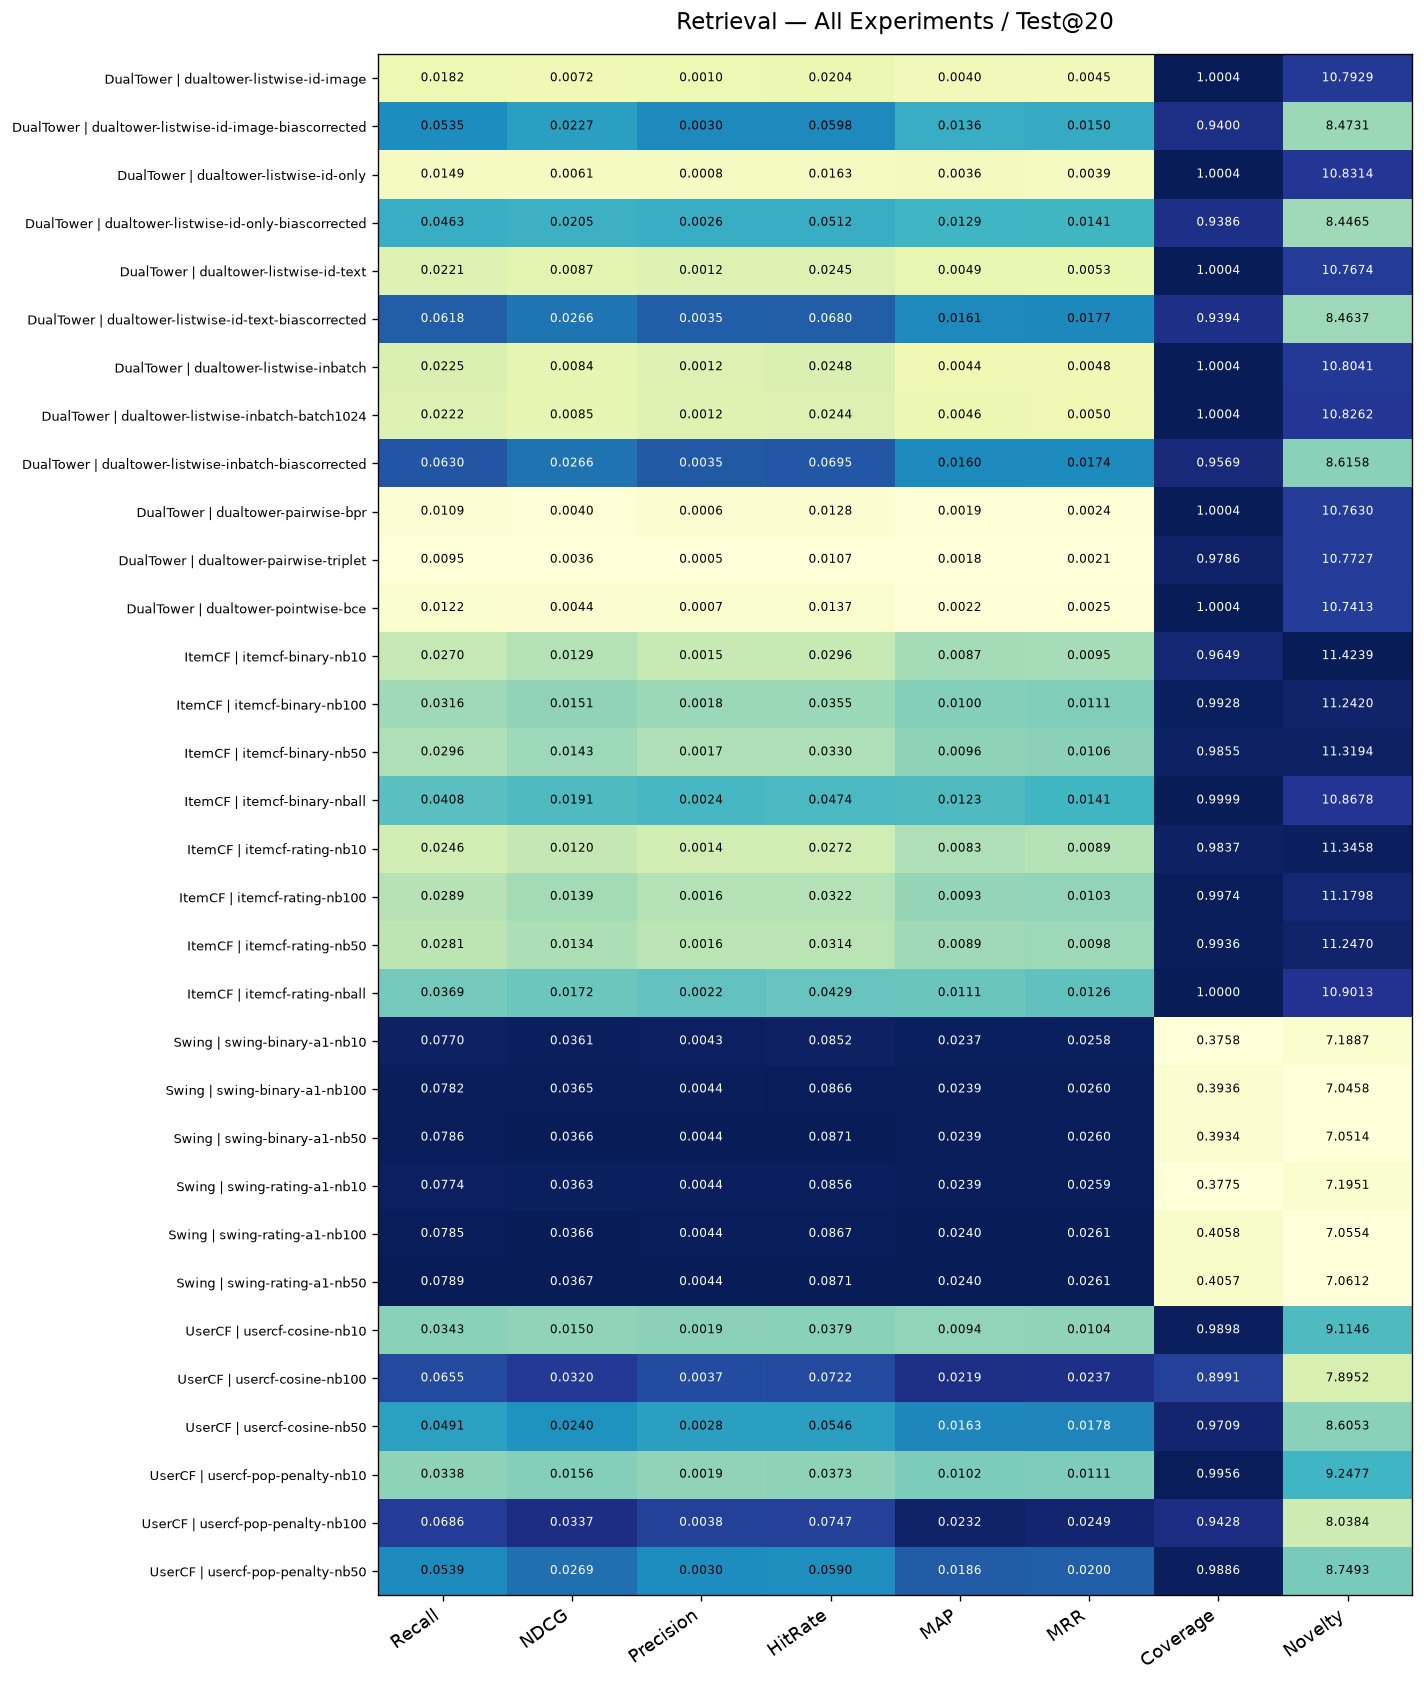

Saved: 01_retrieval_all_experiments_heatmap.png
=== Best Configurations (selected on Validation) ===


,Algorithm,Experiment,Validation_NDCG@20,Validation_Recall@20
82,Swing,swing-binary-a1-nb10,0.037307,0.080802
192,UserCF,usercf-pop-penalty-nb100,0.032281,0.066269
302,DualTower,dualtower-listwise-id-text-biascorrected,0.026340,0.060710
32,ItemCF,itemcf-binary-nball,0.018912,0.040859


=== Selected Models / Test@20 ===


,Algorithm,Experiment,Recall,NDCG,Precision,HitRate,MAP,MRR,Coverage,Novelty
0,ItemCF,itemcf-binary-nball,0.04082,0.01913,0.00244,0.04742,0.01230,0.01411,0.99986,10.86783
1,Swing,swing-binary-a1-nb10,0.07702,0.03610,0.00435,0.08521,0.02372,0.02578,0.37576,7.18871
2,UserCF,usercf-pop-penalty-nb100,0.06856,0.03365,0.00379,0.07472,0.02316,0.02494,0.94281,8.03842
3,DualTower,dualtower-listwise-id-text-biascorrected,0.06179,0.02656,0.00346,0.06804,0.01610,0.01767,0.93941,8.46366


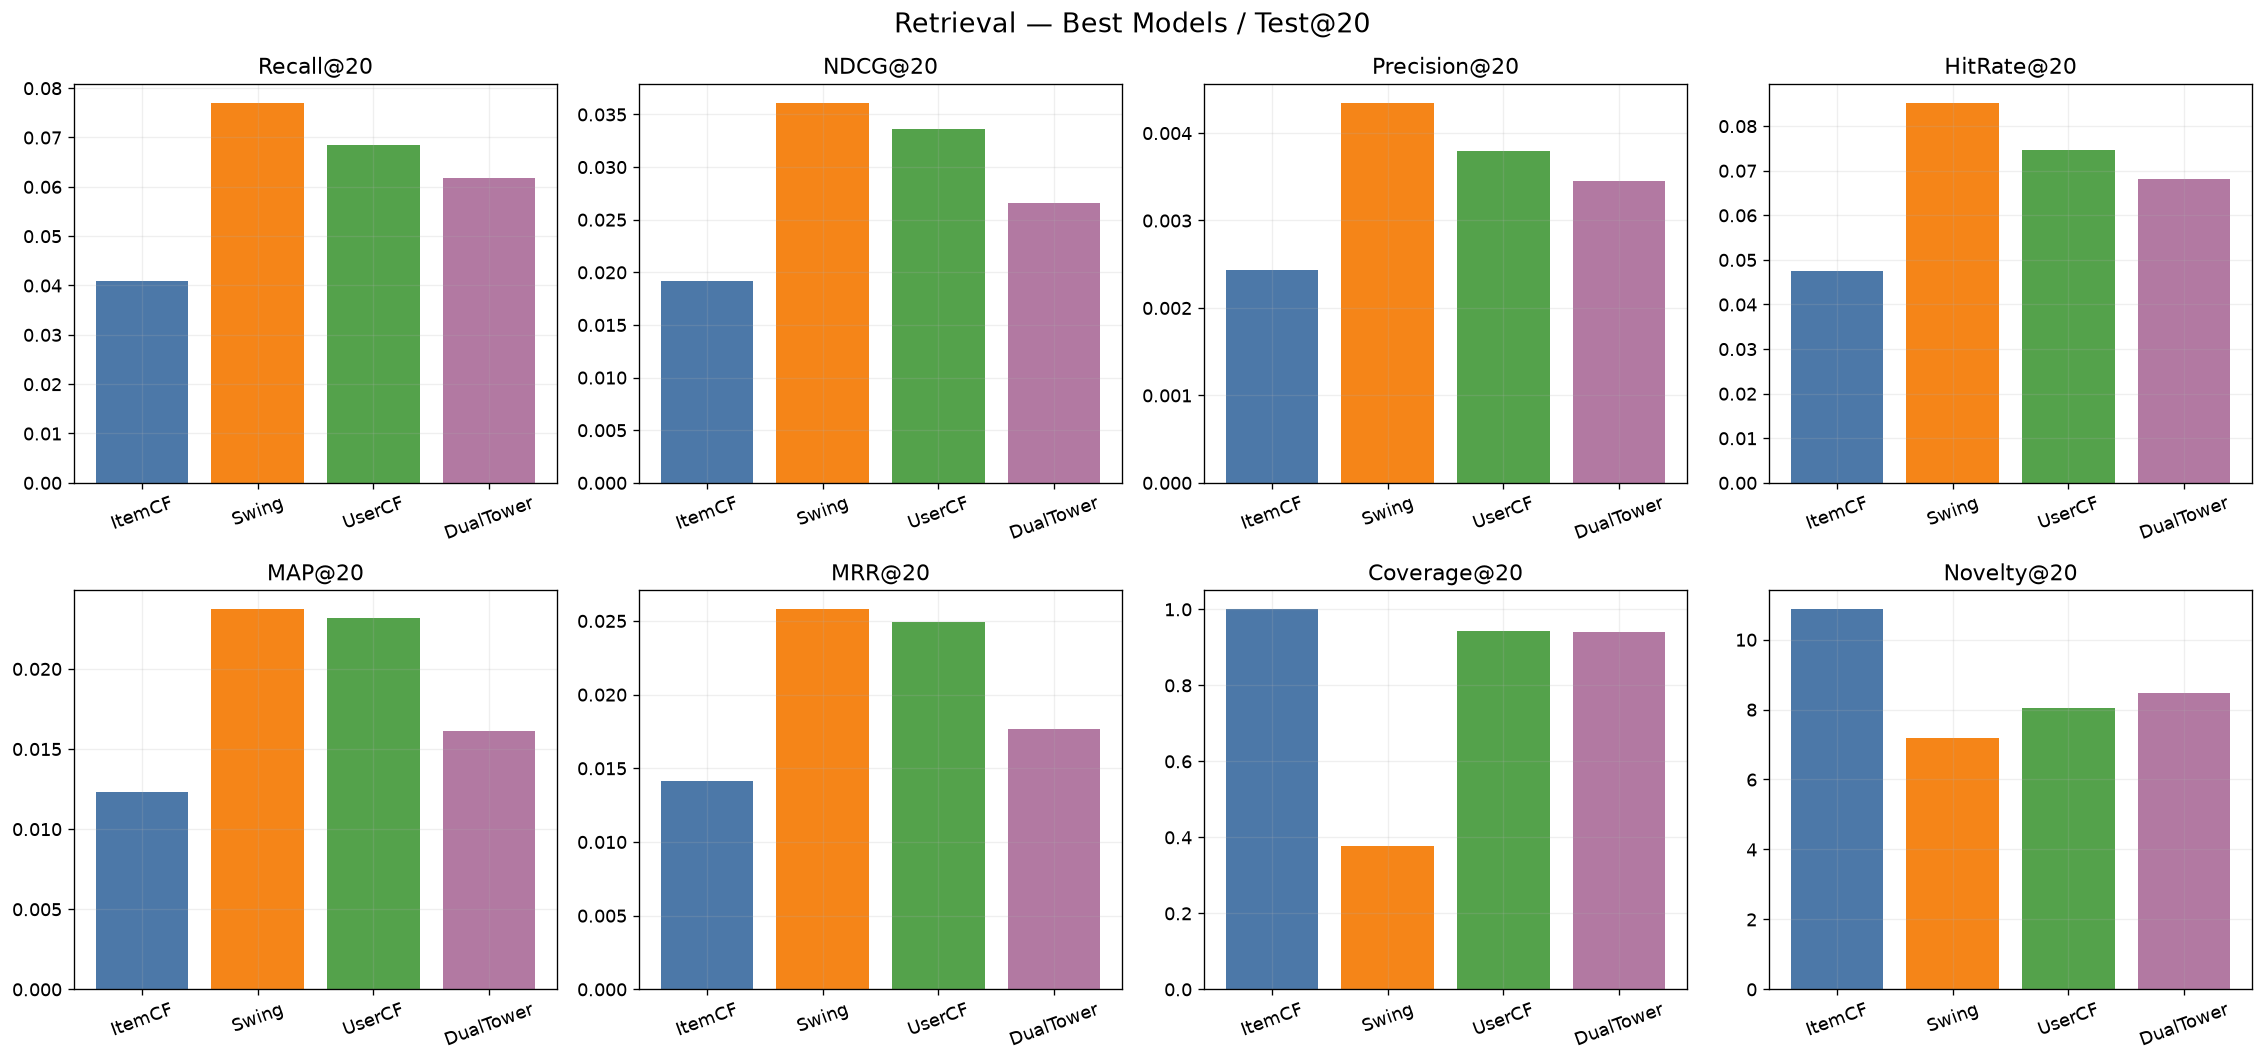

Saved: 02_retrieval_best_test20.png


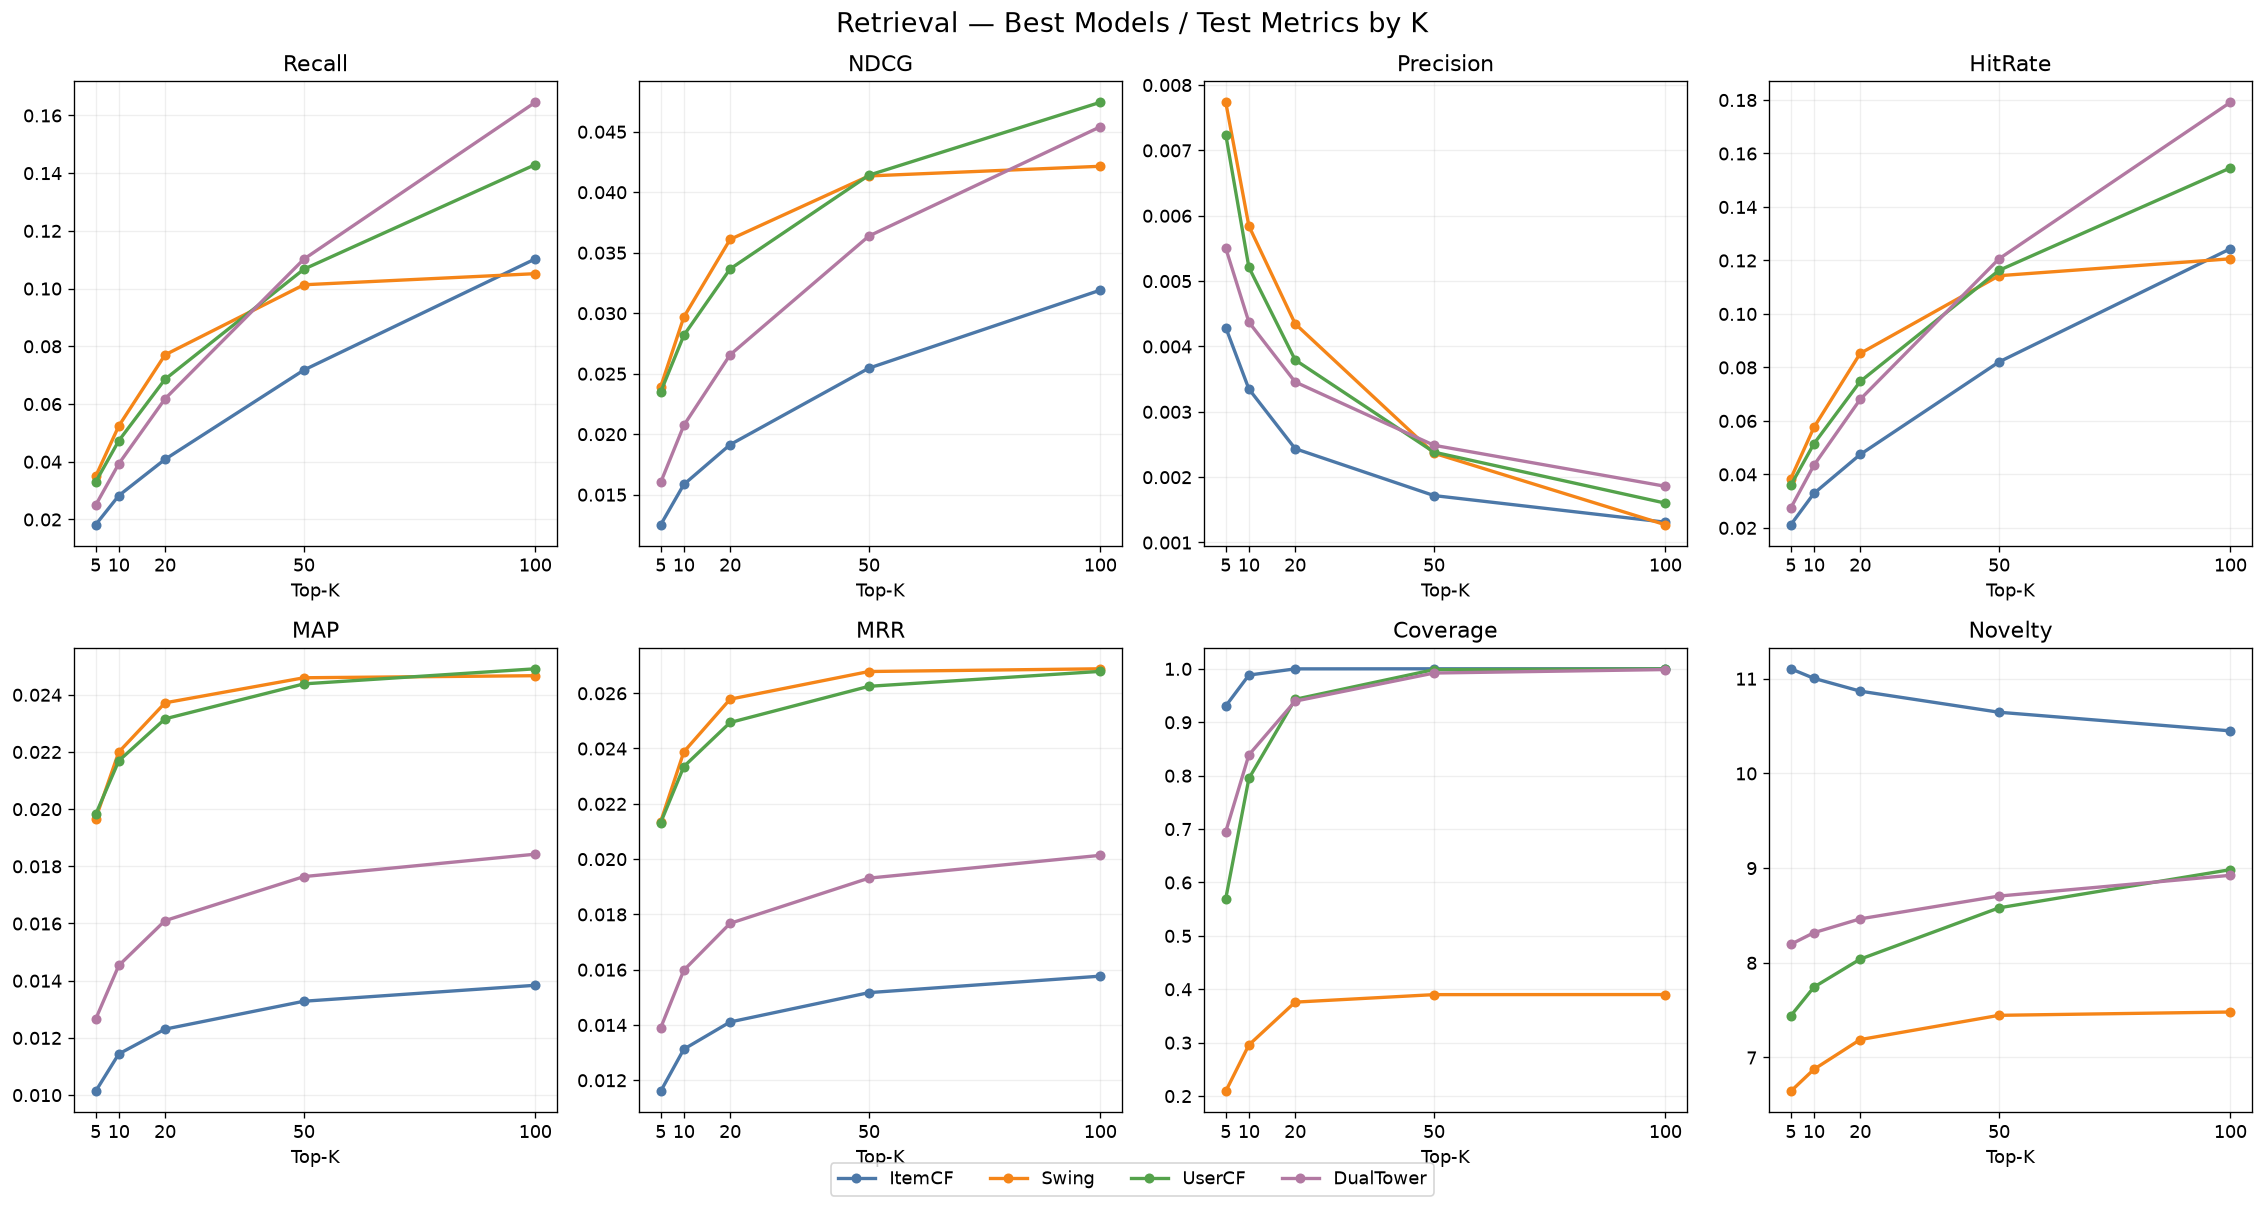

Saved: 03_retrieval_best_metrics_by_k.png


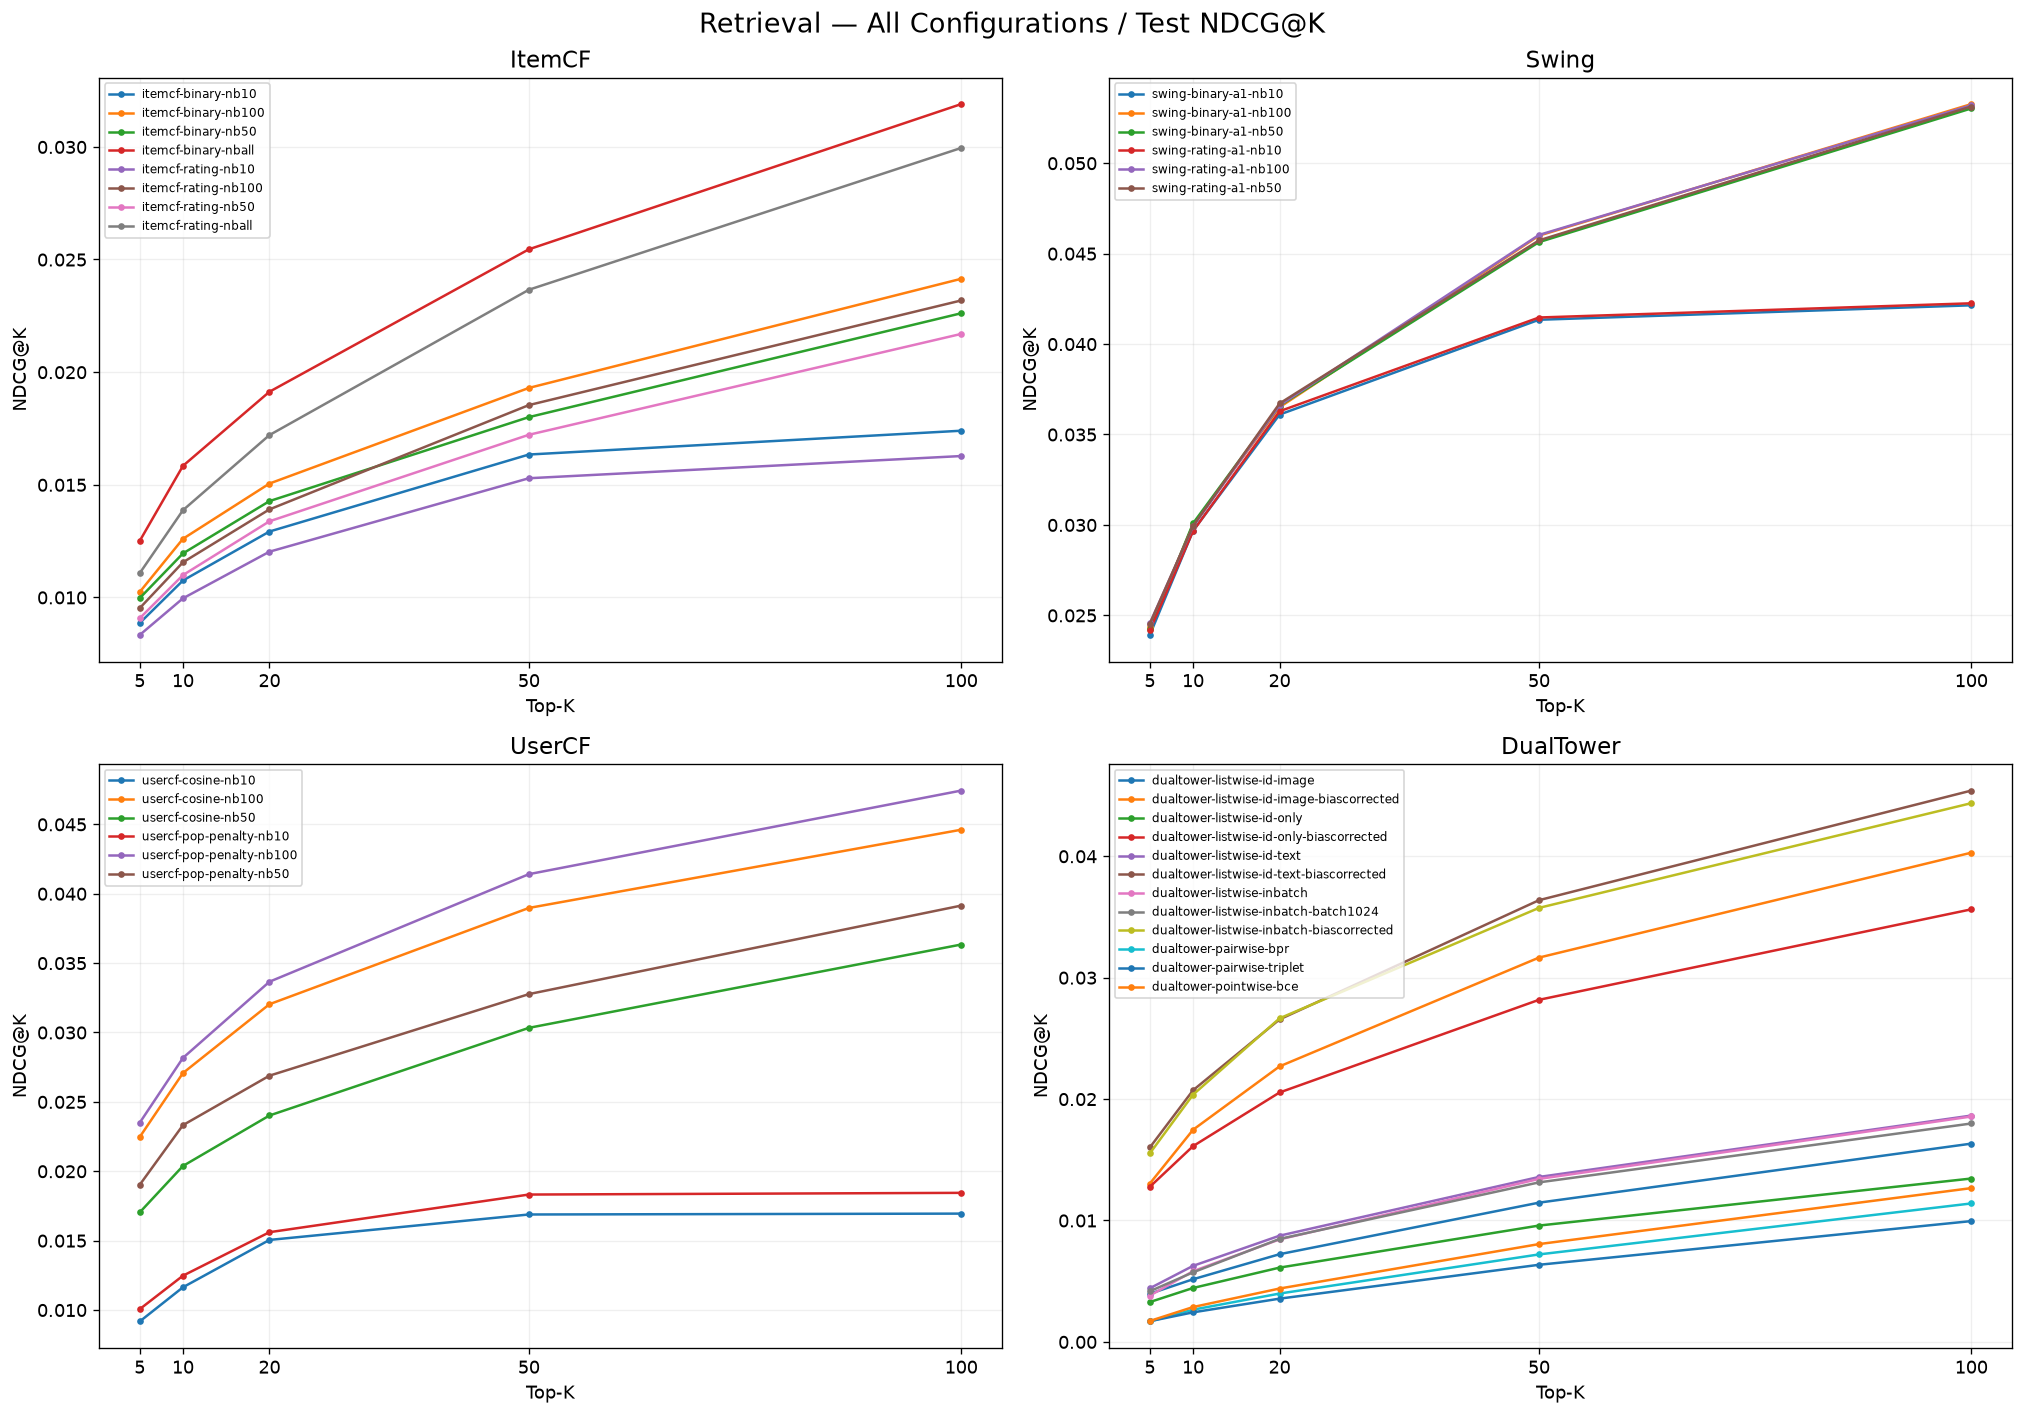

Saved: 04_retrieval_all_ndcg_curves.png


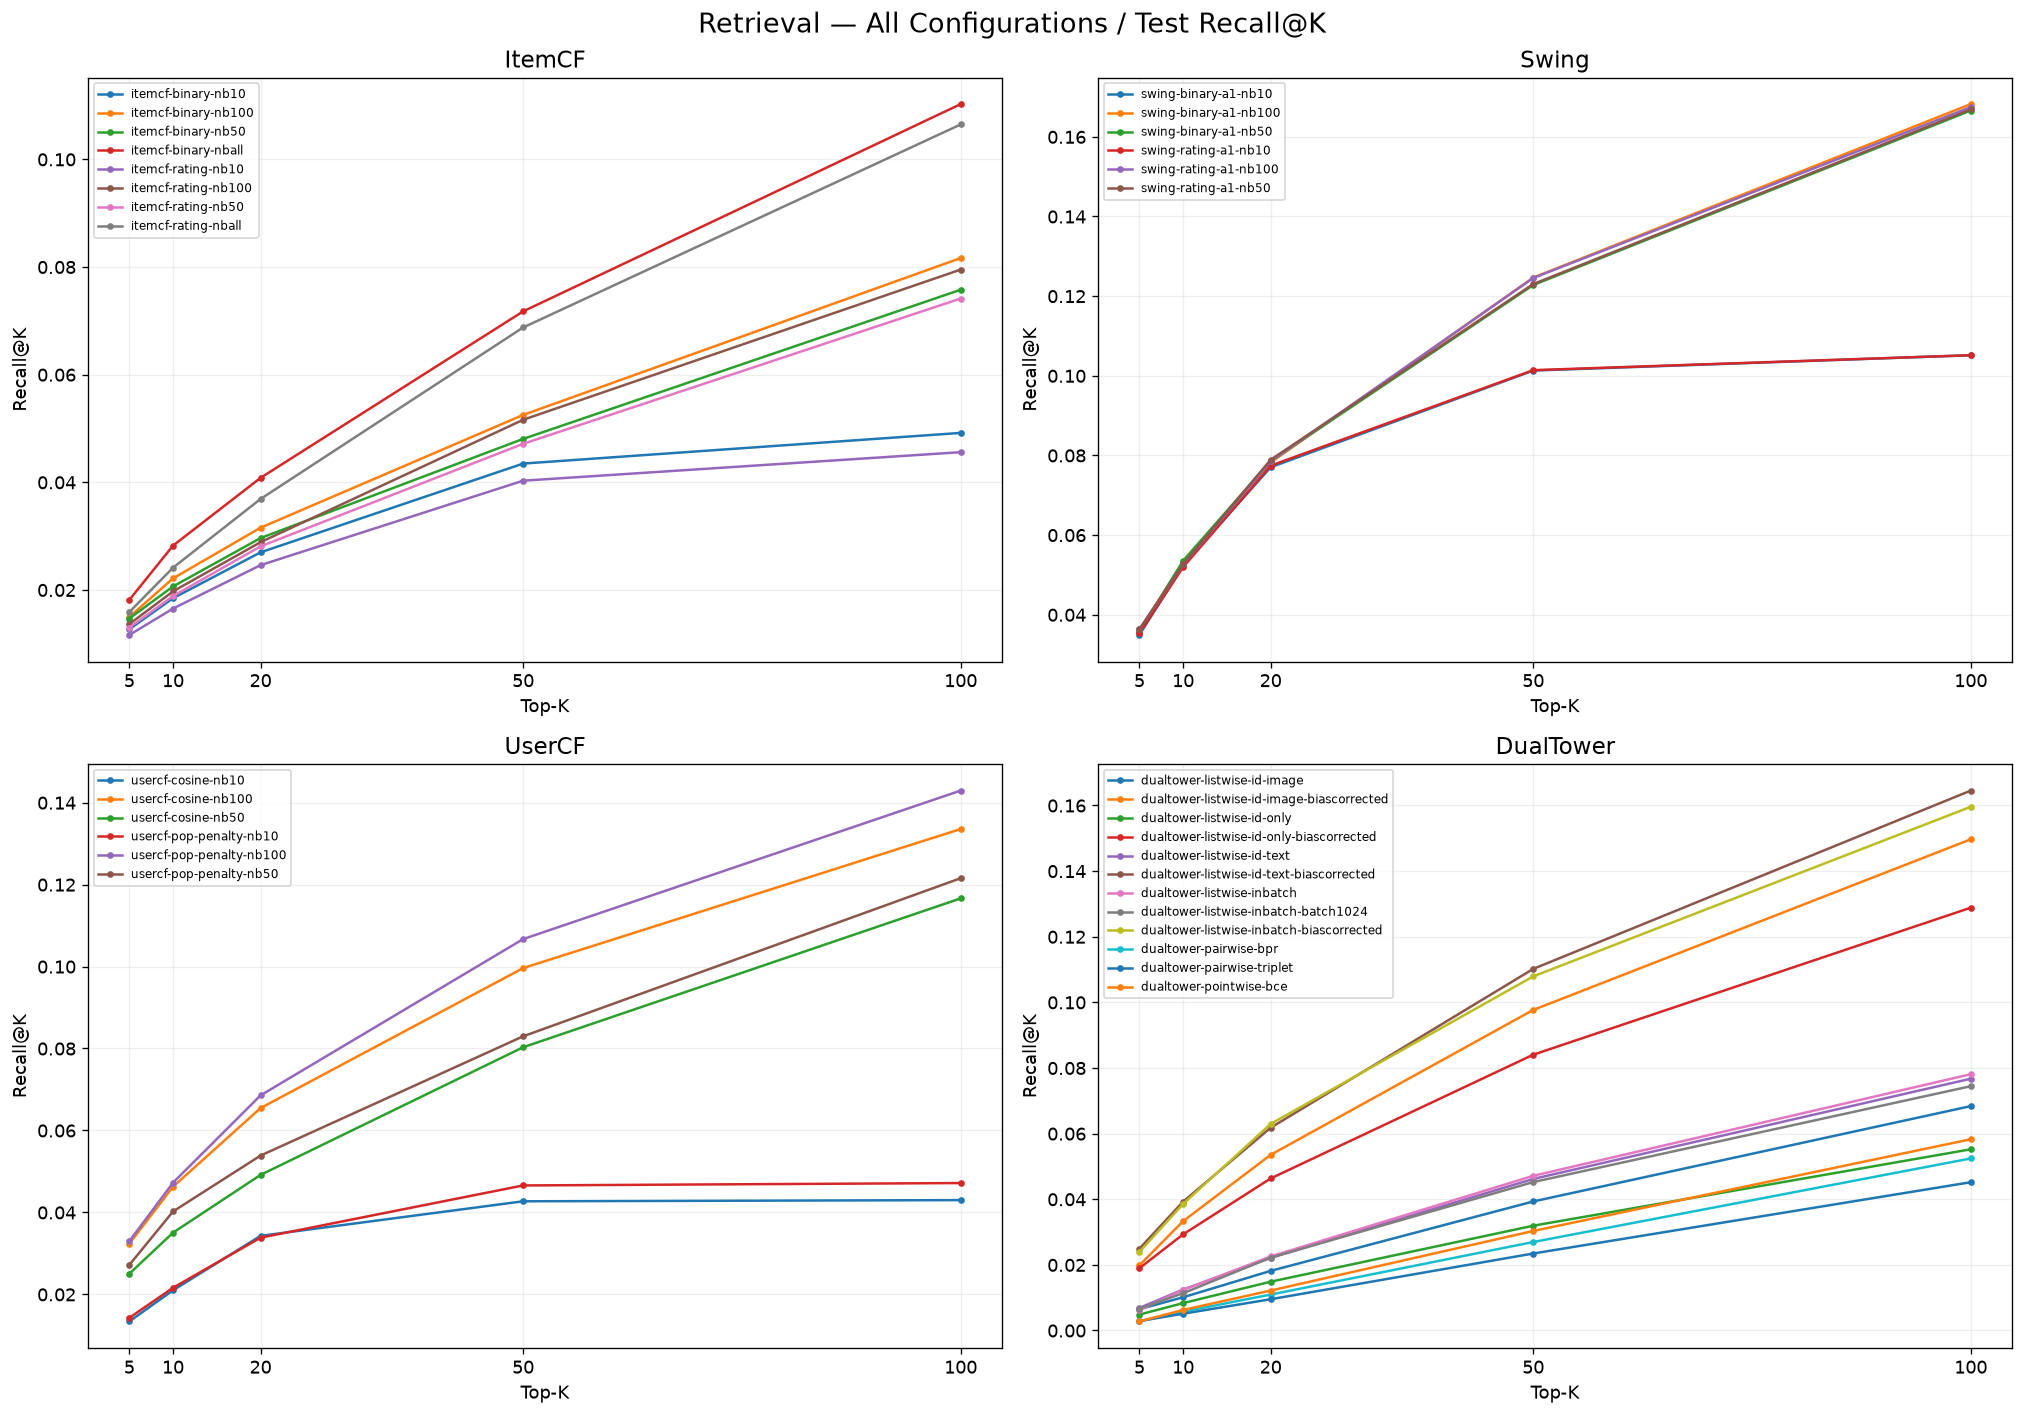

Saved: 05_retrieval_all_recall_curves.png


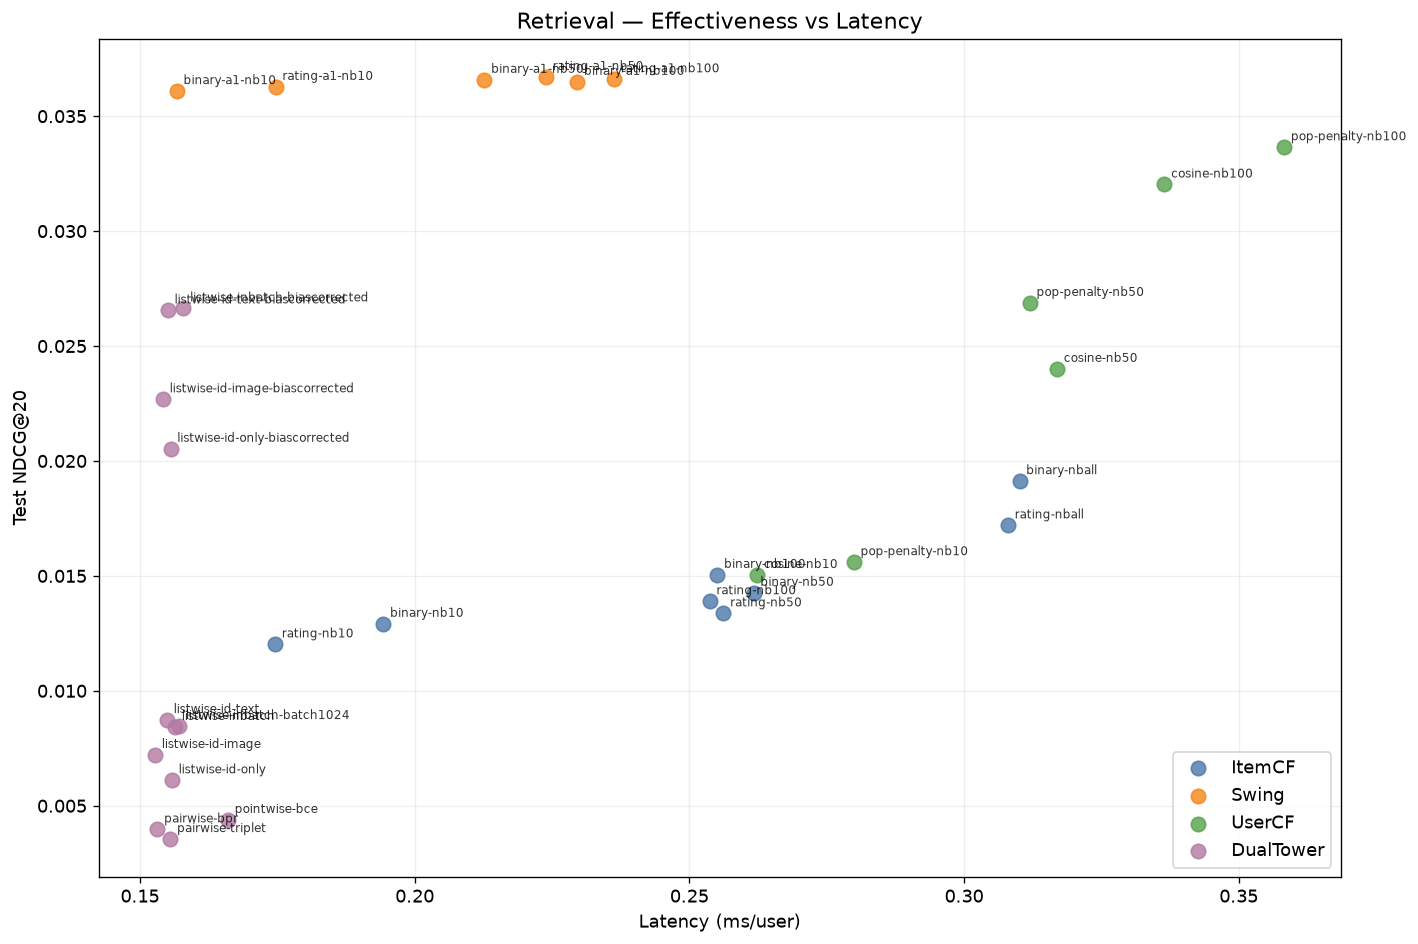

Saved: 06_retrieval_effectiveness_vs_latency.png

=== Retrieval Summary ===
Total experiments: 32
Algorithms: 4

Best Test NDCG@20:


,Algorithm,Experiment,NDCG,Recall
1,Swing,swing-binary-a1-nb10,0.03610,0.07702
2,UserCF,usercf-pop-penalty-nb100,0.03365,0.06856
3,DualTower,dualtower-listwise-id-text-biascorrected,0.02656,0.06179
0,ItemCF,itemcf-binary-nball,0.01913,0.04082



Figures saved to:
F:\Recommendation\RecSys-Lab\results\analysis


In [2]:

# ============================================================
# Cell 2 — Retrieval Comparison
# 32 组召回实验：ItemCF / Swing / UserCF / DualTower
# ============================================================

from matplotlib.colors import Normalize
import textwrap

RETRIEVAL = METRICS[
    METRICS["Algorithm"].isin(
        ["ItemCF", "Swing", "UserCF", "DualTower"]
    )
].copy()

RETRIEVAL_ALGOS = ["ItemCF", "Swing", "UserCF", "DualTower"]
COLORS = {
    "ItemCF": "#4C78A8",
    "Swing": "#F58518",
    "UserCF": "#54A24B",
    "DualTower": "#B279A2"
}

assert not RETRIEVAL.empty, "未找到召回实验指标。"

def metric_table(df, split="Test", k=20):
    return df[
        (df["Split"] == split) &
        (df["K"] == k)
    ].copy()

def plot_metric_heatmap(frame, title, filename):
    """
    每列独立归一化，仅用于显示颜色深浅。
    单元格保留原始数值，不能跨不同指标比较颜色。
    """
    frame = frame.copy()
    values = frame.to_numpy(dtype=float)

    normalized = np.full_like(values, np.nan)
    for j in range(values.shape[1]):
        column = values[:, j]
        finite = np.isfinite(column)
        if not finite.any():
            continue
        low, high = np.nanmin(column), np.nanmax(column)
        normalized[finite, j] = (
            (column[finite] - low) / (high - low)
            if high > low else 0.5
        )

    fig, ax = plt.subplots(
        figsize=(max(12, frame.shape[1] * 1.5),
                 max(5, frame.shape[0] * 0.38 + 2))
    )

    cmap = plt.get_cmap("YlGnBu").copy()
    cmap.set_bad("#eeeeee")
    ax.imshow(normalized, aspect="auto", cmap=cmap, vmin=0, vmax=1)

    ax.set_xticks(range(frame.shape[1]))
    ax.set_xticklabels(frame.columns, rotation=35, ha="right")
    ax.set_yticks(range(frame.shape[0]))
    ax.set_yticklabels(frame.index, fontsize=8)

    for i in range(frame.shape[0]):
        for j in range(frame.shape[1]):
            value = values[i, j]
            if np.isfinite(value):
                ax.text(
                    j, i, f"{value:.4f}",
                    ha="center", va="center", fontsize=7,
                    color="white" if normalized[i, j] > 0.65 else "black"
                )

    ax.set_title(title, fontsize=14, pad=15)
    ax.grid(False)
    save_figure(filename)


# ------------------------------------------------------------
# 1. 全部召回实验：Test@20 指标热力图
# ------------------------------------------------------------

test20 = metric_table(RETRIEVAL, "Test", 20)

available_metrics = [
    m for m in RANKING_METRICS
    if m in test20.columns
]

heatmap_df = (
    test20.set_index(["Algorithm", "Experiment"])[available_metrics]
    .sort_index()
)

heatmap_df.index = [
    f"{algo} | {exp}"
    for algo, exp in heatmap_df.index
]

plot_metric_heatmap(
    heatmap_df,
    "Retrieval — All Experiments / Test@20",
    "01_retrieval_all_experiments_heatmap.png"
)


# ------------------------------------------------------------
# 2. Validation NDCG@20 选择每种算法的最优配置
# ------------------------------------------------------------

valid20 = metric_table(RETRIEVAL, "Validation", 20)
valid20 = valid20.dropna(subset=["NDCG"])

best_config = (
    valid20.sort_values("NDCG", ascending=False)
    .drop_duplicates("Algorithm")
    [["Algorithm", "Experiment", "NDCG", "Recall"]]
    .rename(columns={
        "NDCG": "Validation_NDCG@20",
        "Recall": "Validation_Recall@20"
    })
)

best_test = test20.merge(
    best_config[["Algorithm", "Experiment"]],
    on=["Algorithm", "Experiment"],
    how="inner"
).copy()

best_test["Algorithm"] = pd.Categorical(
    best_test["Algorithm"],
    categories=RETRIEVAL_ALGOS,
    ordered=True
)
best_test = best_test.sort_values("Algorithm")

print("=== Best Configurations (selected on Validation) ===")
display(best_config)

print("=== Selected Models / Test@20 ===")
display(
    best_test[
        ["Algorithm", "Experiment"] + available_metrics
    ].round(5)
)

best_test.to_csv(
    OUTPUT_DIR / "retrieval_best_test20.csv",
    index=False
)


# ------------------------------------------------------------
# 3. 四类召回算法：最优配置的全部 Test 指标
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 4, figsize=(19, 9))
axes = axes.ravel()

for ax, metric in zip(axes, available_metrics):
    for _, row in best_test.iterrows():
        pass

    ax.bar(
        best_test["Algorithm"].astype(str),
        best_test[metric],
        color=[
            COLORS[str(a)]
            for a in best_test["Algorithm"]
        ]
    )
    ax.set_title(f"{metric}@20")
    ax.tick_params(axis="x", rotation=20)

    if metric not in ["Novelty"]:
        ax.set_ylim(bottom=0)

for ax in axes[len(available_metrics):]:
    ax.axis("off")

fig.suptitle(
    "Retrieval — Best Models / Test@20",
    fontsize=16
)
save_figure("02_retrieval_best_test20.png")


# ------------------------------------------------------------
# 4. 最优召回配置：Test 指标随 K 变化
# ------------------------------------------------------------

selected = RETRIEVAL.merge(
    best_config[["Algorithm", "Experiment"]],
    on=["Algorithm", "Experiment"],
    how="inner"
)

selected = selected[selected["Split"] == "Test"]

fig, axes = plt.subplots(2, 4, figsize=(19, 10))
axes = axes.ravel()

for ax, metric in zip(axes, available_metrics):
    for algorithm in RETRIEVAL_ALGOS:
        sub = selected[
            selected["Algorithm"] == algorithm
        ].sort_values("K")

        if sub.empty:
            continue

        ax.plot(
            sub["K"],
            sub[metric],
            marker="o",
            linewidth=2,
            markersize=5,
            label=algorithm,
            color=COLORS[algorithm]
        )

    ax.set_title(metric)
    ax.set_xlabel("Top-K")
    ax.set_xticks(KS)

for ax in axes[len(available_metrics):]:
    ax.axis("off")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc="lower center",
    ncol=4,
    bbox_to_anchor=(0.5, -0.015)
)
fig.suptitle(
    "Retrieval — Best Models / Test Metrics by K",
    fontsize=16
)
fig.subplots_adjust(bottom=0.09)
save_figure("03_retrieval_best_metrics_by_k.png")


# ------------------------------------------------------------
# 5. 算法内部：不同配置的 NDCG@K 曲线
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(17, 12))

for ax, algorithm in zip(axes.ravel(), RETRIEVAL_ALGOS):
    sub = RETRIEVAL[
        (RETRIEVAL["Algorithm"] == algorithm) &
        (RETRIEVAL["Split"] == "Test")
    ]

    for experiment, exp_df in sub.groupby("Experiment"):
        exp_df = exp_df.sort_values("K")

        ax.plot(
            exp_df["K"],
            exp_df["NDCG"],
            marker="o",
            markersize=3,
            linewidth=1.5,
            label=experiment
        )

    ax.set_title(algorithm, fontsize=14)
    ax.set_xlabel("Top-K")
    ax.set_ylabel("NDCG@K")
    ax.set_xticks(KS)
    ax.legend(fontsize=7, loc="best")

fig.suptitle(
    "Retrieval — All Configurations / Test NDCG@K",
    fontsize=16
)
save_figure("04_retrieval_all_ndcg_curves.png")


# ------------------------------------------------------------
# 6. 算法内部：不同配置的 Recall@K 曲线
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(17, 12))

for ax, algorithm in zip(axes.ravel(), RETRIEVAL_ALGOS):
    sub = RETRIEVAL[
        (RETRIEVAL["Algorithm"] == algorithm) &
        (RETRIEVAL["Split"] == "Test")
    ]

    for experiment, exp_df in sub.groupby("Experiment"):
        exp_df = exp_df.sort_values("K")

        ax.plot(
            exp_df["K"],
            exp_df["Recall"],
            marker="o",
            markersize=3,
            linewidth=1.5,
            label=experiment
        )

    ax.set_title(algorithm, fontsize=14)
    ax.set_xlabel("Top-K")
    ax.set_ylabel("Recall@K")
    ax.set_xticks(KS)
    ax.legend(fontsize=7, loc="best")

fig.suptitle(
    "Retrieval — All Configurations / Test Recall@K",
    fontsize=16
)
save_figure("05_retrieval_all_recall_curves.png")


# ------------------------------------------------------------
# 7. 效果与推理延迟的权衡
# ------------------------------------------------------------

latency_col = "Latency(ms/user)"

if latency_col in test20.columns:
    fig, ax = plt.subplots(figsize=(12, 8))

    for algorithm in RETRIEVAL_ALGOS:
        sub = test20[
            test20["Algorithm"] == algorithm
        ].dropna(subset=[latency_col, "NDCG"])

        ax.scatter(
            sub[latency_col],
            sub["NDCG"],
            s=75,
            alpha=0.8,
            label=algorithm,
            color=COLORS[algorithm]
        )

        for _, row in sub.iterrows():
            ax.annotate(
                row["Experiment"].replace(
                    algorithm.lower() + "-", ""
                ),
                (row[latency_col], row["NDCG"]),
                xytext=(4, 4),
                textcoords="offset points",
                fontsize=7,
                alpha=0.8
            )

    ax.set_xlabel("Latency (ms/user)")
    ax.set_ylabel("Test NDCG@20")
    ax.set_title("Retrieval — Effectiveness vs Latency")
    ax.legend()

    save_figure("06_retrieval_effectiveness_vs_latency.png")


# ------------------------------------------------------------
# 8. 输出实验汇总
# ------------------------------------------------------------

print("\n=== Retrieval Summary ===")
print("Total experiments:", RETRIEVAL["Experiment"].nunique())
print("Algorithms:", RETRIEVAL["Algorithm"].nunique())

print("\nBest Test NDCG@20:")
display(
    best_test[
        ["Algorithm", "Experiment", "NDCG", "Recall"]
    ].sort_values("NDCG", ascending=False).round(5)
)

print("\nFigures saved to:")
print(OUTPUT_DIR)


# 3.Multi-Chanel Retrieval

Total retrieval experiments: 32
Total candidate records: 53648763
Unique users: 19445

=== Retrieval Family Summary ===


,Family,Experiments,UniquePairs,UniqueItems,UniqueUsers
0,ItemCF,8,3598512,7047,19445
1,Swing,6,2095411,4020,19413
2,UserCF,6,3243425,7047,19445
3,DualTower,12,16126098,7050,19445


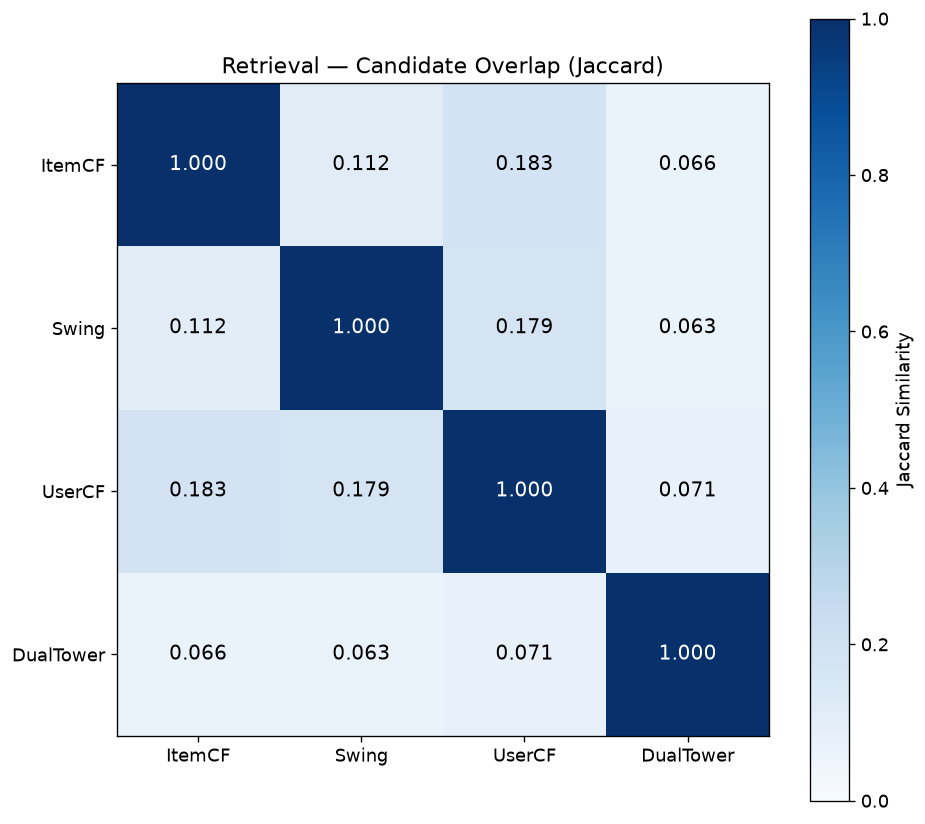

Saved: 07_retrieval_channel_overlap.png


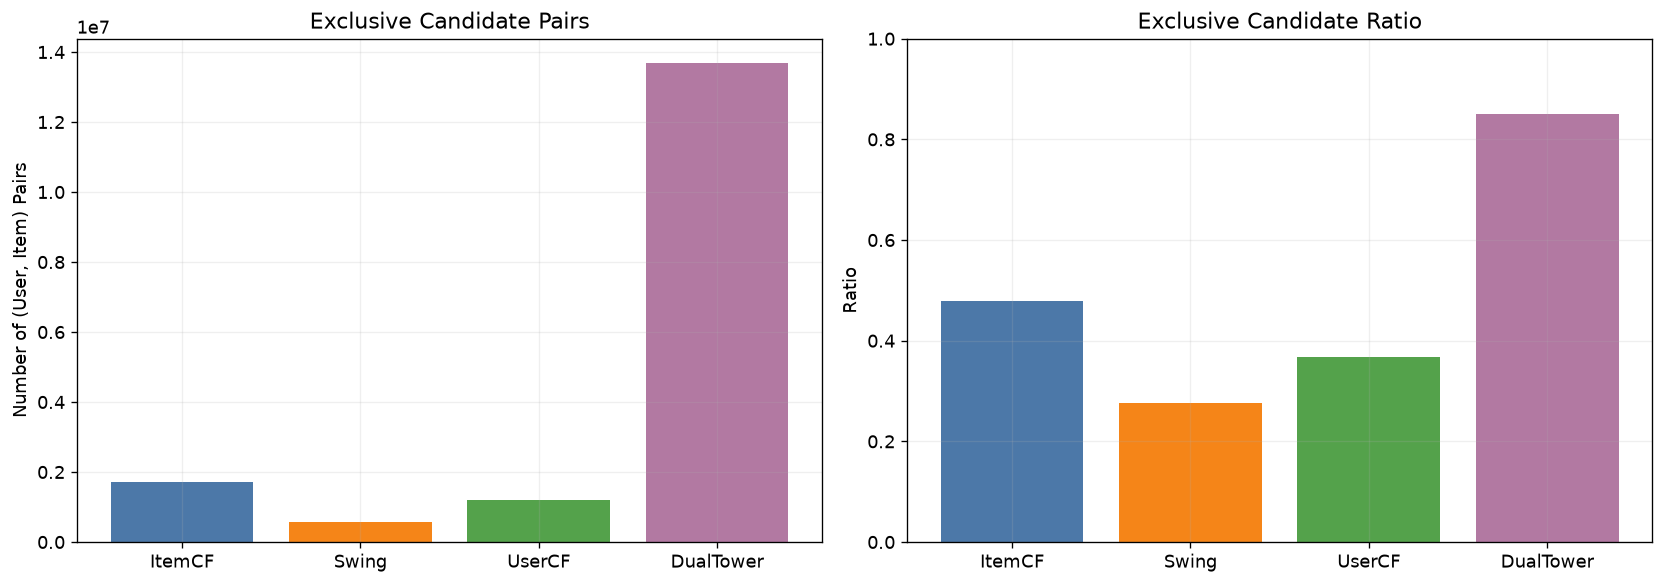

Saved: 08_retrieval_channel_complementarity.png


,Family,UniqueOnly,TotalPairs,UniqueRatio
0,ItemCF,1720602,3598512,0.478143
1,Swing,580203,2095411,0.276892
2,UserCF,1190828,3243425,0.367151
3,DualTower,13696369,16126098,0.849329


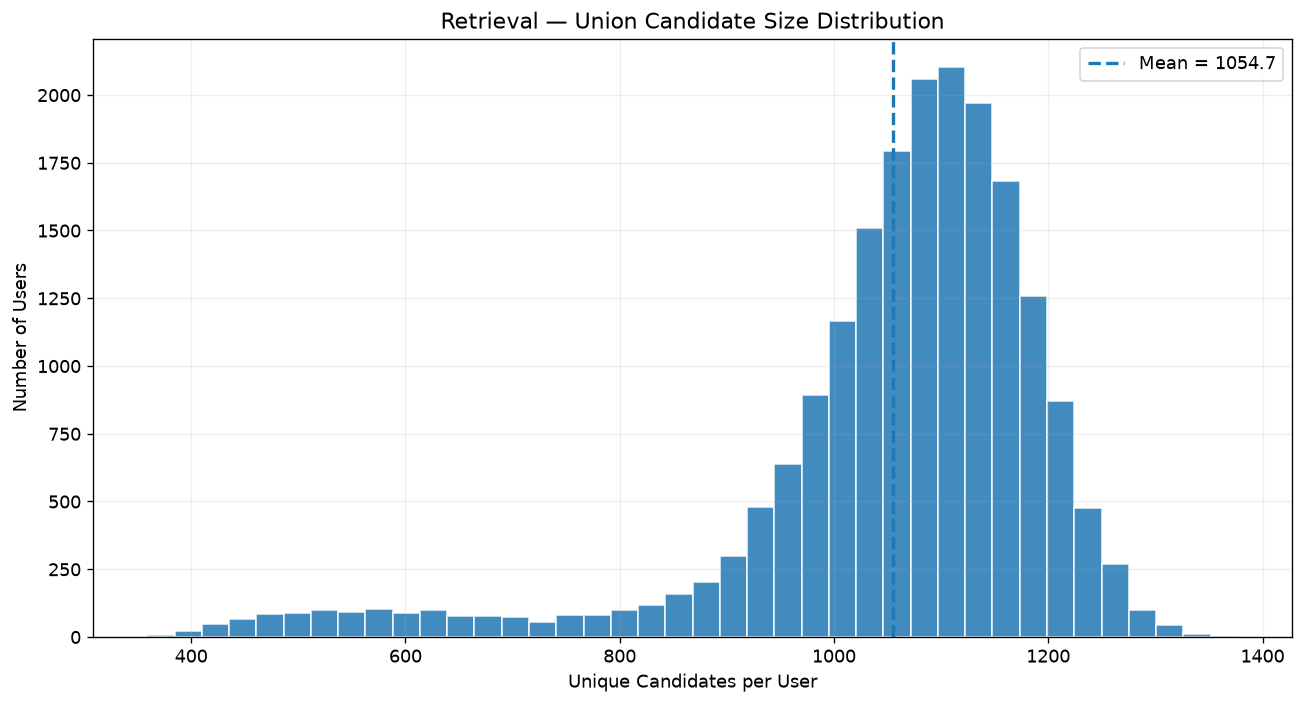

Saved: 09_retrieval_union_candidate_distribution.png

=== Union Candidate Statistics ===


,CandidateCount
count,19445.000000
mean,1054.681306
std,151.620784
min,359.000000
25%,1012.000000
50%,1086.000000
75%,1145.000000
max,1377.000000



RRF Fusion completed.
Candidate pairs: 20508278

=== RRF Fusion / Test ===


,K,Recall,NDCG,HitRate
0,5,0.04096,0.02890,0.04531
1,10,0.05911,0.03490,0.06578
2,20,0.08239,0.04094,0.09159
3,50,0.12343,0.04929,0.13649
4,100,0.17063,0.05716,0.18653


Union Candidate Recall Ceiling: 0.48932


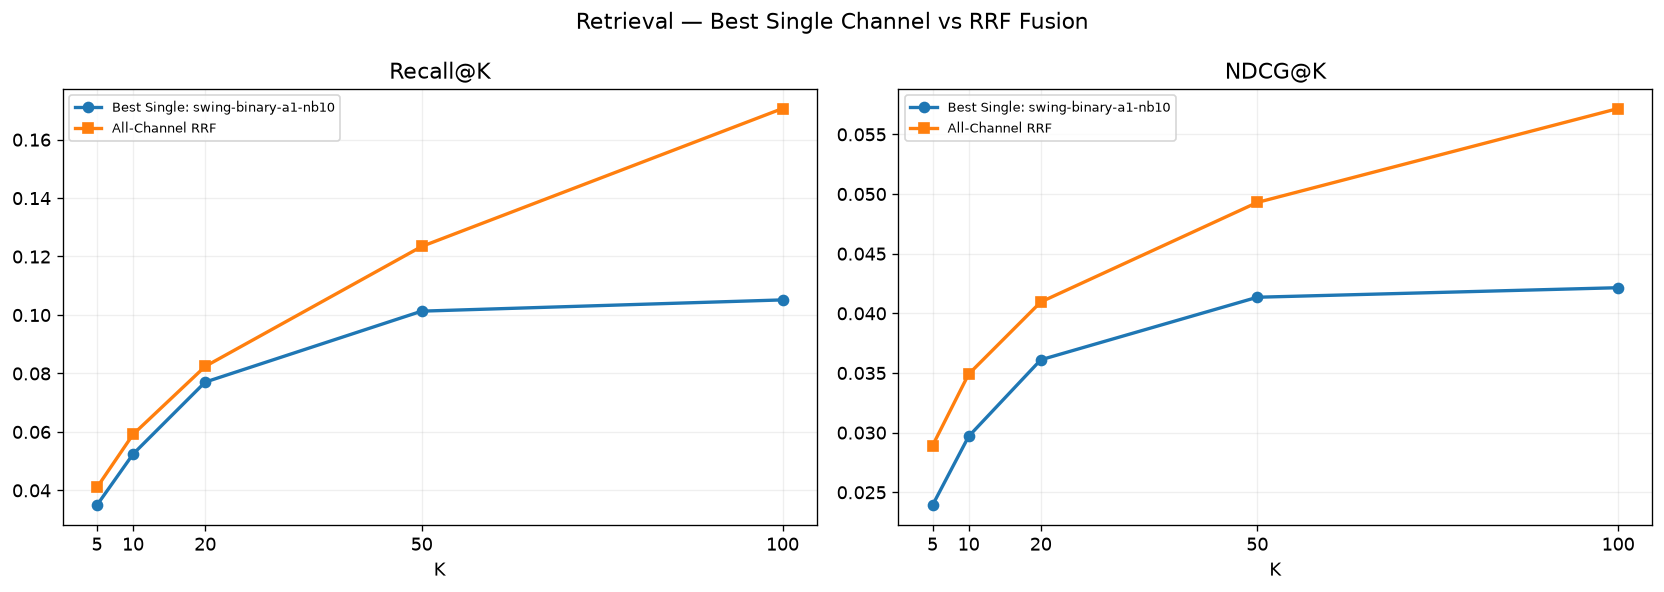

Saved: 10_retrieval_single_vs_rrf.png

Cell 3 completed.


In [5]:

# ============================================================
# Cell 3 — Multi-Channel Retrieval Analysis
# 使用全部召回 Parquet，分析通道互补性与融合效果
# 依赖 Cell 1 的 PROJECT_ROOT、RECALL_FILES、OUTPUT_DIR、KS
# ============================================================

from collections import defaultdict
from itertools import combinations
import re

assert RECALL_FILES, (
    "没有找到召回 Parquet。请确认文件位于项目目录下的 recall 文件夹。"
)

FAMILIES = ["ItemCF", "Swing", "UserCF", "DualTower"]
FAMILY_PREFIX = {
    "ItemCF": "itemcf-",
    "Swing": "swing-",
    "UserCF": "usercf-",
    "DualTower": "dualtower-",
}

# ------------------------------------------------------------
# 1. 读取全部召回结果
# ------------------------------------------------------------

recall_frames = []

for path in RECALL_FILES:
    df = pd.read_parquet(path)

    if not {"userID", "itemID"}.issubset(df.columns):
        print("Skipped:", path)
        continue

    experiment = path.stem

    family = next(
        (
            name for name, prefix in FAMILY_PREFIX.items()
            if experiment.lower().startswith(prefix)
        ),
        None
    )

    if family is None:
        print("Unknown channel, skipped:", experiment)
        continue

    df = df.copy()
    df["userID"] = df["userID"].astype(int)
    df["itemID"] = df["itemID"].astype(int)

    if "rank" not in df.columns:
        if "score" in df.columns:
            df = df.sort_values(
                ["userID", "score"],
                ascending=[True, False]
            )
        df["rank"] = df.groupby("userID").cumcount() + 1

    df["Experiment"] = experiment
    df["Family"] = family

    recall_frames.append(
        df[["userID", "itemID", "rank", "Experiment", "Family"]]
    )

assert recall_frames, "没有可用的召回候选文件。"

RECALL_CANDIDATES = pd.concat(recall_frames, ignore_index=True)

# 同一实验中，每个用户-商品只保留最靠前的排名
RECALL_CANDIDATES = (
    RECALL_CANDIDATES
    .sort_values("rank")
    .drop_duplicates(["Experiment", "userID", "itemID"])
)

print("Total retrieval experiments:",
      RECALL_CANDIDATES.Experiment.nunique())
print("Total candidate records:", len(RECALL_CANDIDATES))
print("Unique users:", RECALL_CANDIDATES.userID.nunique())


# ------------------------------------------------------------
# 2. 按算法家族合并候选集
# ------------------------------------------------------------

family_pairs = {
    family: set(
        map(
            tuple,
            RECALL_CANDIDATES.loc[
                RECALL_CANDIDATES.Family == family,
                ["userID", "itemID"]
            ].to_numpy()
        )
    )
    for family in FAMILIES
}

family_summary = pd.DataFrame([
    {
        "Family": family,
        "Experiments": RECALL_CANDIDATES.loc[
            RECALL_CANDIDATES.Family == family,
            "Experiment"
        ].nunique(),
        "UniquePairs": len(family_pairs[family]),
        "UniqueItems": len({
            item for _, item in family_pairs[family]
        }),
        "UniqueUsers": len({
            user for user, _ in family_pairs[family]
        }),
    }
    for family in FAMILIES
])

print("\n=== Retrieval Family Summary ===")
display(family_summary)

family_summary.to_csv(
    OUTPUT_DIR / "retrieval_family_summary.csv",
    index=False
)


# ------------------------------------------------------------
# 3. 通道重合度：Jaccard Similarity
# J(A,B) = |A ∩ B| / |A ∪ B|
# 基于 (userID, itemID) 配对，而不是仅比较商品 ID
# ------------------------------------------------------------

jaccard = pd.DataFrame(
    np.zeros((len(FAMILIES), len(FAMILIES))),
    index=FAMILIES,
    columns=FAMILIES
)

for a in FAMILIES:
    for b in FAMILIES:
        union = family_pairs[a] | family_pairs[b]
        intersection = family_pairs[a] & family_pairs[b]

        jaccard.loc[a, b] = (
            len(intersection) / len(union)
            if union else np.nan
        )

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(jaccard.values, cmap="Blues", vmin=0, vmax=1)

ax.set_xticks(range(len(FAMILIES)))
ax.set_xticklabels(FAMILIES)
ax.set_yticks(range(len(FAMILIES)))
ax.set_yticklabels(FAMILIES)

for i in range(len(FAMILIES)):
    for j in range(len(FAMILIES)):
        value = jaccard.iloc[i, j]
        ax.text(
            j, i, f"{value:.3f}",
            ha="center", va="center",
            color="white" if value > 0.6 else "black",
            fontsize=12
        )

ax.set_title("Retrieval — Candidate Overlap (Jaccard)")
fig.colorbar(im, ax=ax, label="Jaccard Similarity")
ax.grid(False)

save_figure("07_retrieval_channel_overlap.png")


# ------------------------------------------------------------
# 4. 每个通道独有的候选数量
# ------------------------------------------------------------

unique_rows = []

for family in FAMILIES:
    others = set().union(
        *[
            family_pairs[other]
            for other in FAMILIES
            if other != family
        ]
    )

    unique_pairs = family_pairs[family] - others

    unique_rows.append({
        "Family": family,
        "UniqueOnly": len(unique_pairs),
        "TotalPairs": len(family_pairs[family]),
        "UniqueRatio": (
            len(unique_pairs) / len(family_pairs[family])
            if family_pairs[family] else 0
        )
    })

unique_df = pd.DataFrame(unique_rows)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(
    unique_df.Family,
    unique_df.UniqueOnly,
    color=[COLORS[f] for f in unique_df.Family]
)
axes[0].set_title("Exclusive Candidate Pairs")
axes[0].set_ylabel("Number of (User, Item) Pairs")

axes[1].bar(
    unique_df.Family,
    unique_df.UniqueRatio,
    color=[COLORS[f] for f in unique_df.Family]
)
axes[1].set_title("Exclusive Candidate Ratio")
axes[1].set_ylabel("Ratio")
axes[1].set_ylim(0, 1)

save_figure("08_retrieval_channel_complementarity.png")

display(unique_df)


# ------------------------------------------------------------
# 5. 合并全部召回实验后的候选规模分布
# ------------------------------------------------------------

UNION_CANDIDATES = (
    RECALL_CANDIDATES[["userID", "itemID"]]
    .drop_duplicates()
)

candidate_counts = (
    UNION_CANDIDATES.groupby("userID")
    .size()
    .rename("CandidateCount")
)

fig, ax = plt.subplots(figsize=(11, 6))

ax.hist(
    candidate_counts.values,
    bins=40,
    edgecolor="white",
    alpha=0.85
)

ax.axvline(
    candidate_counts.mean(),
    linestyle="--",
    linewidth=2,
    label=f"Mean = {candidate_counts.mean():.1f}"
)

ax.set_xlabel("Unique Candidates per User")
ax.set_ylabel("Number of Users")
ax.set_title("Retrieval — Union Candidate Size Distribution")
ax.legend()

save_figure("09_retrieval_union_candidate_distribution.png")

print("\n=== Union Candidate Statistics ===")
display(candidate_counts.describe().to_frame())


# ------------------------------------------------------------
# 6. RRF 融合排序
#
# RRF(u,i) = sum over experiments 1 / (c + rank_e(u,i))
# 不同实验分数尺度不同，因此使用 rank 而不是 score。
# 每个实验都作为独立通道参与融合。
# ------------------------------------------------------------

RRF_C = 60

rrf = RECALL_CANDIDATES.copy()

rrf["rrf_score"] = 1.0 / (RRF_C + rrf["rank"])

RRF_RANKING = (
    rrf.groupby(["userID", "itemID"], as_index=False)
    .agg(
        score=("rrf_score", "sum"),
        channel_count=("Experiment", "nunique")
    )
    .sort_values(
        ["userID", "score", "itemID"],
        ascending=[True, False, True]
    )
)

RRF_RANKING["rank"] = (
    RRF_RANKING.groupby("userID").cumcount() + 1
)

print("\nRRF Fusion completed.")
print("Candidate pairs:", len(RRF_RANKING))

# 保存完整融合排序，方便后续与 ThreeTower 比较
RRF_RANKING.to_parquet(
    OUTPUT_DIR / "retrieval_rrf_all_candidates.parquet",
    index=False
)


# ------------------------------------------------------------
# 7. 可选：加载 Amazon Baby 标签，计算融合效果
#
# 自动搜索 baby.inter；找不到时跳过有监督评估。
# 只使用 Test 标签计算效果。
# ------------------------------------------------------------

inter_matches = list(PROJECT_ROOT.rglob("baby.inter"))

if not inter_matches:
    print(
        "\n[Notice] 未找到 baby.inter，"
        "跳过融合排序的 Recall/NDCG 评估。"
    )
    print(
        "可将 baby.inter 放入项目 data 目录后重新运行。"
    )
else:
    inter_path = inter_matches[0]
    interactions = pd.read_csv(inter_path, sep="\t")

    train_inter = interactions[
        interactions["x_label"] == 0
    ]
    test_inter = interactions[
        interactions["x_label"] == 2
    ]

    TEST_TRUTH = {
        int(u): set(g["itemID"].astype(int))
        for u, g in test_inter.groupby("userID")
    }

    TRAIN_SEEN = {
        int(u): set(g["itemID"].astype(int))
        for u, g in train_inter.groupby("userID")
    }

    # 与粗排一致：过滤训练历史
    seen_pairs = (
        train_inter[["userID", "itemID"]]
        .drop_duplicates()
        .assign(_seen=1)
    )

    filtered_rrf = RRF_RANKING.merge(
        seen_pairs,
        on=["userID", "itemID"],
        how="left"
    )

    filtered_rrf = filtered_rrf[
        filtered_rrf["_seen"].isna()
    ].drop(columns="_seen")

    # 排除历史后重新排序
    filtered_rrf = filtered_rrf.sort_values(
        ["userID", "score", "itemID"],
        ascending=[True, False, True]
    )

    filtered_rrf["rank"] = (
        filtered_rrf.groupby("userID").cumcount() + 1
    )

    rrf_dict = {
        int(u): g["itemID"].astype(int).tolist()
        for u, g in filtered_rrf.groupby("userID")
    }

    # 统一 Top-K 评估：未召回的用户按 0 分计
    def evaluate_topk(ranking, ground_truth, ks=KS):
        rows = []
        users = sorted(ground_truth)

        for k in ks:
            recalls, ndcgs, hitrates = [], [], []

            for u in users:
                truth = ground_truth[u]
                recs = ranking.get(u, [])[:k]

                hits = np.array(
                    [int(i in truth) for i in recs],
                    dtype=float
                )

                recalls.append(
                    hits.sum() / len(truth)
                )

                dcg = np.sum(
                    hits / np.log2(
                        np.arange(2, len(hits) + 2)
                    )
                )

                ideal_len = min(len(truth), k)
                idcg = np.sum(
                    1 / np.log2(
                        np.arange(2, ideal_len + 2)
                    )
                )

                ndcgs.append(
                    dcg / idcg if idcg > 0 else 0
                )

                hitrates.append(float(hits.sum() > 0))

            rows.append({
                "K": k,
                "Recall": np.mean(recalls),
                "NDCG": np.mean(ndcgs),
                "HitRate": np.mean(hitrates)
            })

        return pd.DataFrame(rows)

    rrf_metrics = evaluate_topk(
        rrf_dict, TEST_TRUTH
    )

    rrf_metrics.to_csv(
        OUTPUT_DIR / "retrieval_rrf_test_metrics.csv",
        index=False
    )

    # 计算完整并集的 Recall 上限
    union_dict = {
        int(u): set(g["itemID"].astype(int))
        for u, g in UNION_CANDIDATES.groupby("userID")
    }

    union_ceiling = np.mean([
        len(truth & union_dict.get(u, set())) / len(truth)
        for u, truth in TEST_TRUTH.items()
    ])

    print("\n=== RRF Fusion / Test ===")
    display(rrf_metrics.round(5))
    print(f"Union Candidate Recall Ceiling: {union_ceiling:.5f}")

    # 绘制 RRF 与最佳单路召回的对比
    best_single = (
        best_test.sort_values("NDCG", ascending=False)
        .iloc[0]
    )

    single_name = best_single["Experiment"]

    single_curves = RETRIEVAL[
        (RETRIEVAL["Experiment"] == single_name) &
        (RETRIEVAL["Split"] == "Test")
    ].sort_values("K")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    for ax, metric in zip(axes, ["Recall", "NDCG"]):
        ax.plot(
            single_curves["K"],
            single_curves[metric],
            marker="o",
            linewidth=2,
            label=f"Best Single: {single_name}"
        )

        ax.plot(
            rrf_metrics["K"],
            rrf_metrics[metric],
            marker="s",
            linewidth=2,
            label="All-Channel RRF"
        )

        ax.set_title(f"{metric}@K")
        ax.set_xlabel("K")
        ax.set_xticks(KS)
        ax.legend(fontsize=8)

    fig.suptitle(
        "Retrieval — Best Single Channel vs RRF Fusion"
    )

    save_figure("10_retrieval_single_vs_rrf.png")

print("\nCell 3 completed.")


# 4.Pre-Ranking Comparison

=== ThreeTower / Validation@20 ===


,Variant,Experiment,Recall,NDCG,Precision,HitRate,MAP,MRR,Coverage,Novelty
322,none,threetower-none,0.03476,0.01212,0.00183,0.03651,0.00591,0.00620,0.46658,7.65151
332,linear,threetower-linear,0.04831,0.01805,0.00252,0.05024,0.00976,0.01010,0.44189,7.58192
342,mlp,threetower-mlp,0.04232,0.01684,0.00222,0.04423,0.00975,0.01013,0.72783,8.07914
352,fm,threetower-fm,0.03957,0.01593,0.00204,0.04078,0.00939,0.00967,0.63374,8.08911
362,dcn2,threetower-dcn2,0.05011,0.02062,0.00257,0.05132,0.01242,0.01272,0.81311,8.34851
372,dcn3,threetower-dcn3,0.04948,0.02055,0.00255,0.05096,0.01248,0.01276,0.84149,8.01117



=== ThreeTower / Test@20 ===


,Variant,Experiment,Recall,NDCG,Precision,HitRate,MAP,MRR,Coverage,Novelty
327,none,threetower-none,0.03781,0.01357,0.00207,0.04124,0.00671,0.00729,0.46658,7.65151
337,linear,threetower-linear,0.05066,0.01924,0.00273,0.05436,0.01039,0.01115,0.44189,7.58192
347,mlp,threetower-mlp,0.04280,0.01821,0.00232,0.04618,0.01111,0.01198,0.72783,8.07914
357,fm,threetower-fm,0.04215,0.01733,0.00224,0.04474,0.01033,0.01081,0.63374,8.08911
367,dcn2,threetower-dcn2,0.04921,0.02096,0.00261,0.05210,0.01289,0.01365,0.81311,8.34851
377,dcn3,threetower-dcn3,0.05002,0.02114,0.00265,0.05282,0.01295,0.01351,0.84149,8.01117


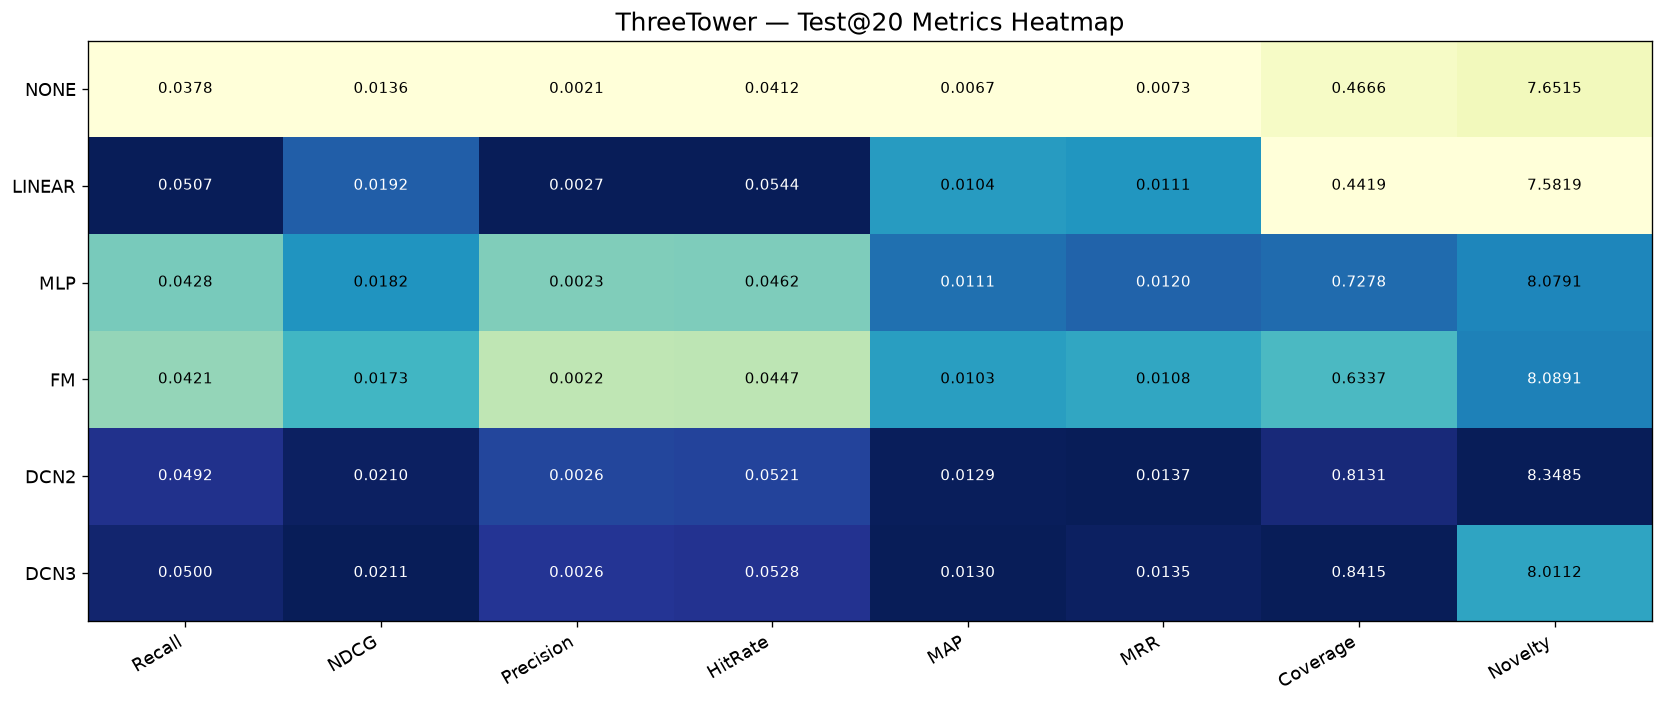

Saved: 11_threetower_metrics_heatmap.png


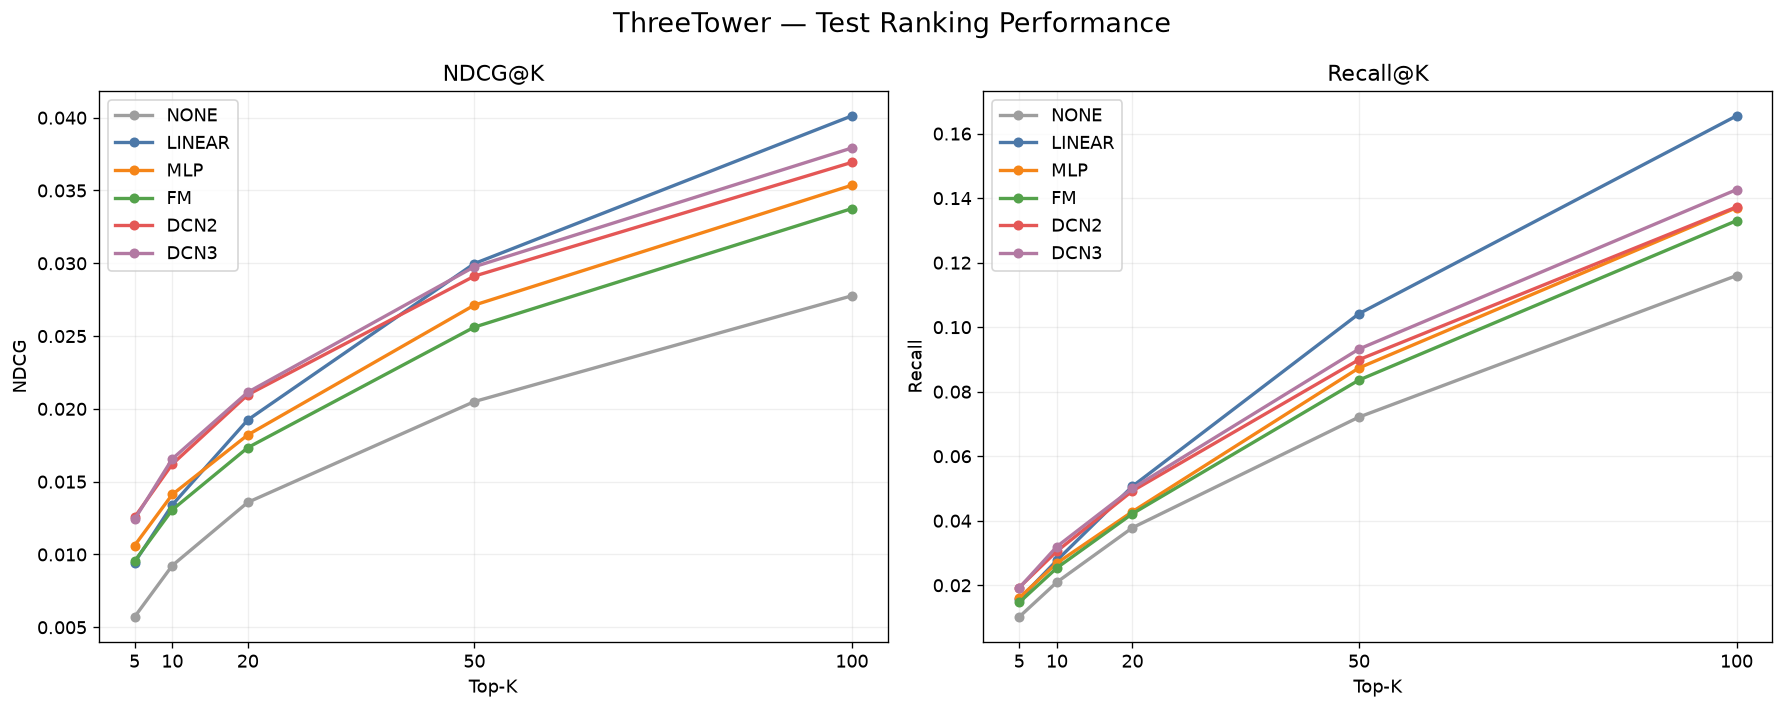

Saved: 12_threetower_ndcg_recall_curves.png


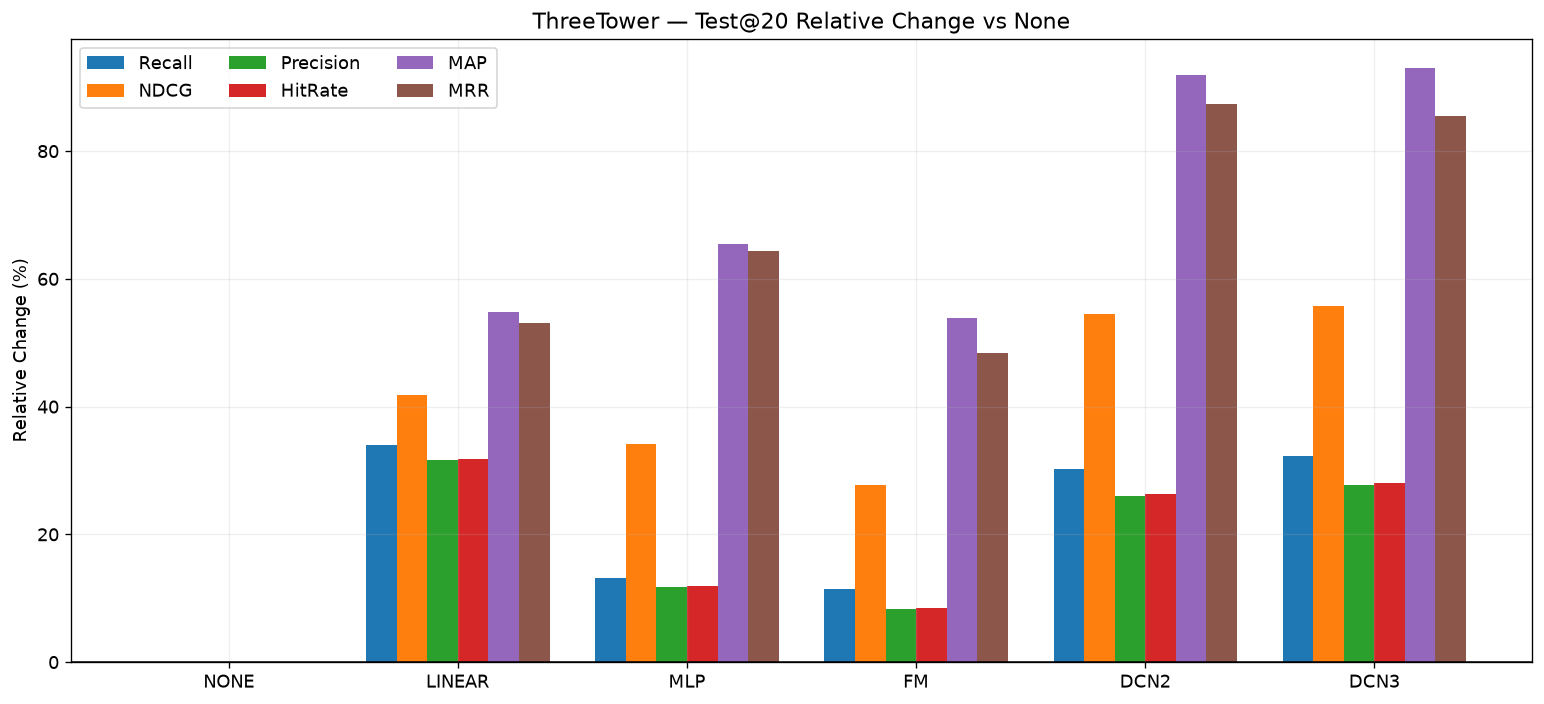

Saved: 13_threetower_relative_lift.png

=== Relative Change vs None (%) ===


,Recall,NDCG,Precision,HitRate,MAP,MRR
Variant,,,,,,
none,0.00,0.00,0.00,0.00,0.00,0.00
linear,33.98,41.73,31.64,31.80,54.82,53.00
mlp,13.20,34.13,11.79,11.97,65.49,64.35
fm,11.48,27.70,8.31,8.48,53.87,48.39
dcn2,30.17,54.44,25.93,26.31,91.97,87.38
dcn3,32.30,55.72,27.67,28.05,92.96,85.46


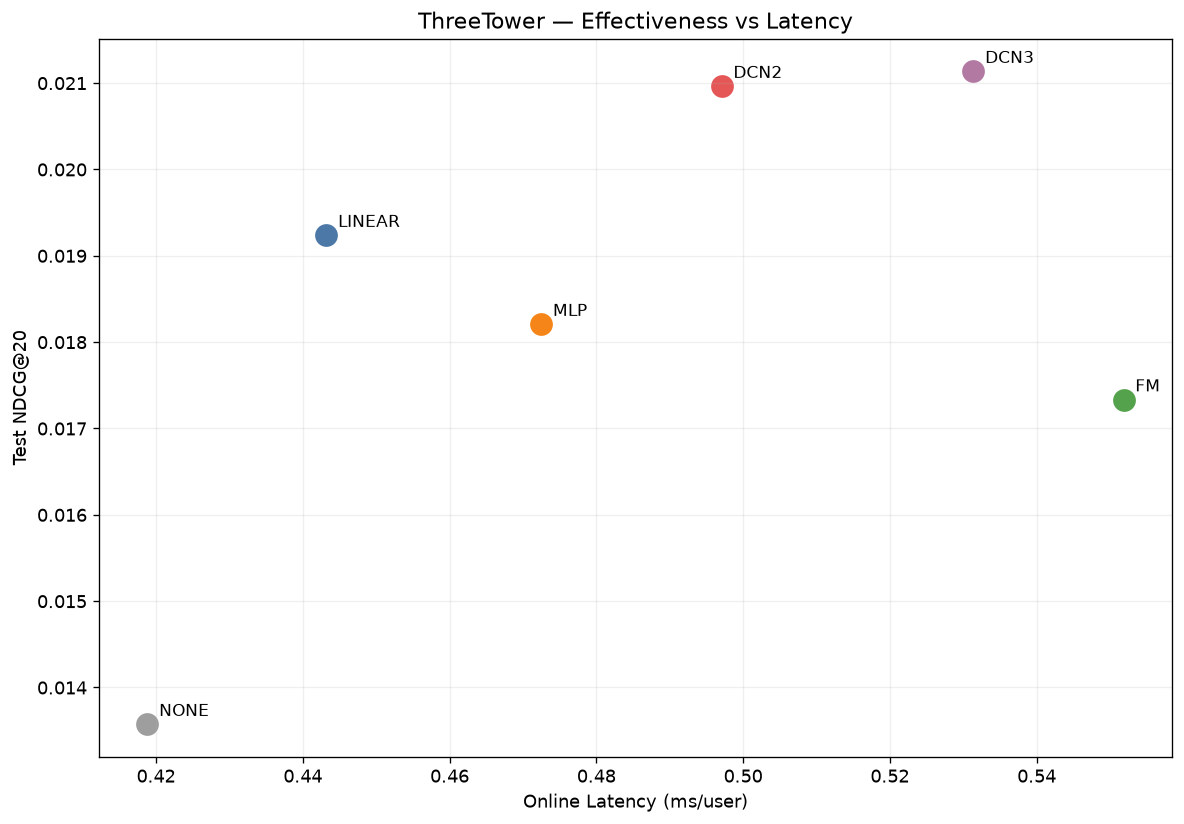

Saved: 14_threetower_effectiveness_vs_latency.png


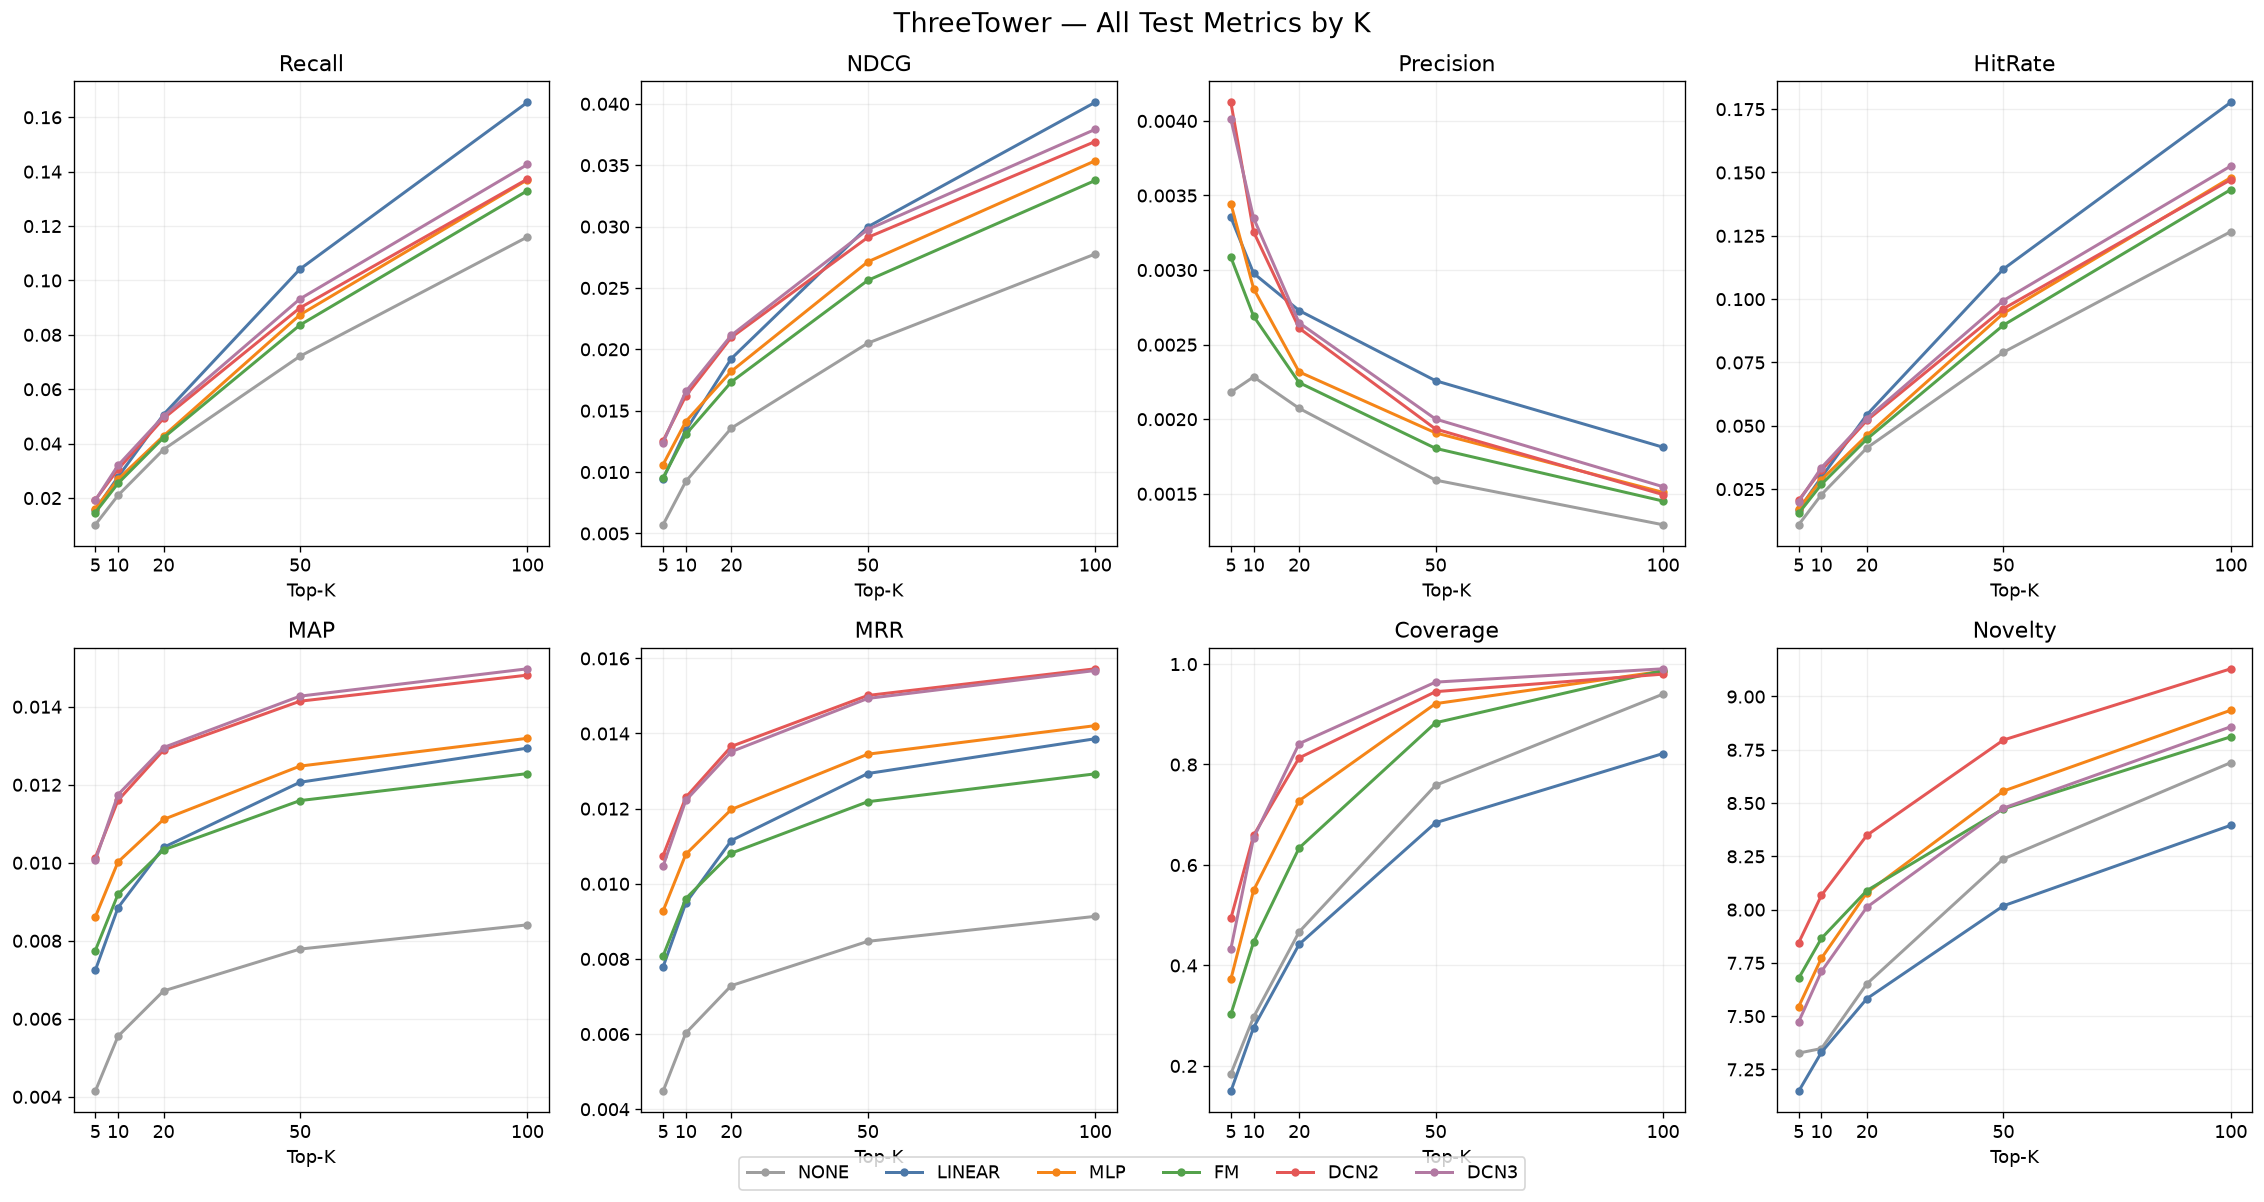

Saved: 15_threetower_all_metrics_by_k.png

=== Best Pre-Ranking Configuration ===
Selected by: Validation NDCG@20
Variant: DCN2
Experiment: threetower-dcn2
Validation NDCG@20: 0.020619
Test NDCG@20: 0.020963
Test Recall@20: 0.049214

Cell 4 completed.
Figures saved to: F:\Recommendation\RecSys-Lab\results\analysis


In [6]:

# ============================================================
# Cell 4 — Pre-Ranking Comparison
# ThreeTower: None / Linear / MLP / FM / DCN2 / DCN3
# 依赖 Cell 1：METRICS、OUTPUT_DIR、KS、save_figure
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. 加载 ThreeTower 实验指标
# ------------------------------------------------------------

PRERANK = METRICS[
    METRICS["Algorithm"] == "ThreeTower"
].copy()

assert not PRERANK.empty, "未找到 ThreeTower 指标，请检查 Cell 1。"

VARIANTS = ["none", "linear", "mlp", "fm", "dcn2", "dcn3"]

PRERANK["Variant"] = (
    PRERANK["Experiment"]
    .str.replace("threetower-", "", regex=False)
    .str.lower()
)

PRERANK = PRERANK[
    PRERANK["Variant"].isin(VARIANTS)
].copy()

PRERANK["Variant"] = pd.Categorical(
    PRERANK["Variant"],
    categories=VARIANTS,
    ordered=True
)

PRERANK = PRERANK.sort_values(["Variant", "Split", "K"])

METRIC_COLS = [
    m for m in [
        "Recall", "NDCG", "Precision", "HitRate",
        "MAP", "MRR", "Coverage", "Novelty"
    ]
    if m in PRERANK.columns
]

VAL20 = PRERANK[
    (PRERANK["Split"] == "Validation") &
    (PRERANK["K"] == 20)
].copy().sort_values("Variant")

TEST20 = PRERANK[
    (PRERANK["Split"] == "Test") &
    (PRERANK["K"] == 20)
].copy().sort_values("Variant")

assert len(TEST20) == 6, (
    f"预期 6 组 Test@20，实际 {len(TEST20)} 组。"
)

print("=== ThreeTower / Validation@20 ===")
display(
    VAL20[["Variant", "Experiment"] + METRIC_COLS]
    .round(5)
)

print("\n=== ThreeTower / Test@20 ===")
display(
    TEST20[["Variant", "Experiment"] + METRIC_COLS]
    .round(5)
)


# ------------------------------------------------------------
# 2. 六种粗排结构：Test@20 全指标热力图
# 每列单独归一化颜色，格内保留原始指标值
# ------------------------------------------------------------

heatmap = (
    TEST20.set_index("Variant")[METRIC_COLS]
    .astype(float)
)

raw = heatmap.to_numpy()

scaled = np.zeros_like(raw, dtype=float)

for j in range(raw.shape[1]):
    column = raw[:, j]
    low = np.nanmin(column)
    high = np.nanmax(column)

    scaled[:, j] = (
        (column - low) / (high - low)
        if high > low else 0.5
    )

fig, ax = plt.subplots(figsize=(14, 6))

im = ax.imshow(
    scaled,
    cmap="YlGnBu",
    aspect="auto",
    vmin=0,
    vmax=1
)

ax.set_xticks(range(len(METRIC_COLS)))
ax.set_xticklabels(METRIC_COLS, rotation=30, ha="right")

ax.set_yticks(range(len(VARIANTS)))
ax.set_yticklabels([v.upper() for v in VARIANTS])

for i in range(raw.shape[0]):
    for j in range(raw.shape[1]):
        ax.text(
            j, i,
            f"{raw[i, j]:.4f}",
            ha="center",
            va="center",
            fontsize=9,
            color="white" if scaled[i, j] > 0.65 else "black"
        )

ax.set_title("ThreeTower — Test@20 Metrics Heatmap", fontsize=15)
ax.grid(False)

save_figure("11_threetower_metrics_heatmap.png")


# ------------------------------------------------------------
# 3. 六种结构：Test NDCG@K 与 Recall@K
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

VARIANT_COLORS = {
    "none": "#9E9E9E",
    "linear": "#4C78A8",
    "mlp": "#F58518",
    "fm": "#54A24B",
    "dcn2": "#E45756",
    "dcn3": "#B279A2"
}

for ax, metric in zip(axes, ["NDCG", "Recall"]):

    for variant in VARIANTS:
        sub = PRERANK[
            (PRERANK["Split"] == "Test") &
            (PRERANK["Variant"] == variant)
        ].sort_values("K")

        ax.plot(
            sub["K"],
            sub[metric],
            marker="o",
            linewidth=2,
            markersize=5,
            label=variant.upper(),
            color=VARIANT_COLORS[variant]
        )

    ax.set_title(f"{metric}@K", fontsize=13)
    ax.set_xlabel("Top-K")
    ax.set_ylabel(metric)
    ax.set_xticks(KS)
    ax.legend()

fig.suptitle(
    "ThreeTower — Test Ranking Performance",
    fontsize=16
)

save_figure("12_threetower_ndcg_recall_curves.png")


# ------------------------------------------------------------
# 4. 相对 None 的性能提升（Test@20）
#
# Lift = (Metric_model - Metric_none) / Metric_none
# 注意：仅对效果指标计算，避免误把 Novelty/Coverage
# 的变化当作单调的质量提升
# ------------------------------------------------------------

LIFT_METRICS = [
    m for m in [
        "Recall", "NDCG", "Precision",
        "HitRate", "MAP", "MRR"
    ]
    if m in TEST20.columns
]

baseline = TEST20[
    TEST20["Variant"] == "none"
].iloc[0]

lift_rows = []

for _, row in TEST20.iterrows():
    record = {"Variant": str(row["Variant"])}

    for metric in LIFT_METRICS:
        base = float(baseline[metric])
        current = float(row[metric])

        record[metric] = (
            (current - base) / base * 100
            if base != 0 else np.nan
        )

    lift_rows.append(record)

LIFT = pd.DataFrame(lift_rows).set_index("Variant")

fig, ax = plt.subplots(figsize=(13, 6))

x = np.arange(len(VARIANTS))
bar_width = 0.8 / len(LIFT_METRICS)

for j, metric in enumerate(LIFT_METRICS):
    ax.bar(
        x - 0.4 + bar_width * (j + 0.5),
        LIFT.reindex(VARIANTS)[metric],
        width=bar_width,
        label=metric
    )

ax.axhline(0, color="black", linewidth=0.9)
ax.set_xticks(x)
ax.set_xticklabels([v.upper() for v in VARIANTS])
ax.set_ylabel("Relative Change (%)")
ax.set_title("ThreeTower — Test@20 Relative Change vs None")
ax.legend(ncol=3)

save_figure("13_threetower_relative_lift.png")

print("\n=== Relative Change vs None (%) ===")
display(LIFT.round(2))


# ------------------------------------------------------------
# 5. NDCG@20 与在线推理延迟的权衡
# 注意：该延迟仅比较 ThreeTower 内部结构。
# ------------------------------------------------------------

LATENCY_COL = "Latency(ms/user)"

if LATENCY_COL in TEST20.columns:

    fig, ax = plt.subplots(figsize=(10, 7))

    for _, row in TEST20.iterrows():
        variant = str(row["Variant"])

        ax.scatter(
            row[LATENCY_COL],
            row["NDCG"],
            s=160,
            color=VARIANT_COLORS[variant],
            label=variant.upper()
        )

        ax.annotate(
            variant.upper(),
            (row[LATENCY_COL], row["NDCG"]),
            xytext=(7, 5),
            textcoords="offset points",
            fontsize=10
        )

    ax.set_xlabel("Online Latency (ms/user)")
    ax.set_ylabel("Test NDCG@20")
    ax.set_title("ThreeTower — Effectiveness vs Latency")

    save_figure("14_threetower_effectiveness_vs_latency.png")


# ------------------------------------------------------------
# 6. 六种结构：所有 Test 指标随 K 的变化
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 4, figsize=(19, 10))
axes = axes.ravel()

for ax, metric in zip(axes, METRIC_COLS):

    for variant in VARIANTS:
        sub = PRERANK[
            (PRERANK["Split"] == "Test") &
            (PRERANK["Variant"] == variant)
        ].sort_values("K")

        ax.plot(
            sub["K"],
            sub[metric],
            marker="o",
            markersize=4,
            linewidth=1.8,
            color=VARIANT_COLORS[variant],
            label=variant.upper()
        )

    ax.set_title(metric)
    ax.set_xlabel("Top-K")
    ax.set_xticks(KS)

for ax in axes[len(METRIC_COLS):]:
    ax.axis("off")

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=6,
    bbox_to_anchor=(0.5, -0.01)
)

fig.suptitle(
    "ThreeTower — All Test Metrics by K",
    fontsize=16
)

fig.subplots_adjust(bottom=0.1)

save_figure("15_threetower_all_metrics_by_k.png")


# ------------------------------------------------------------
# 7. 选择最优粗排结构
# 只使用 Validation NDCG@20 选择，不使用 Test 调参
# ------------------------------------------------------------

BEST_VARIANT_ROW = (
    VAL20.sort_values("NDCG", ascending=False)
    .iloc[0]
)

BEST_VARIANT = str(BEST_VARIANT_ROW["Variant"])
BEST_EXPERIMENT = BEST_VARIANT_ROW["Experiment"]

best_test_row = TEST20[
    TEST20["Experiment"] == BEST_EXPERIMENT
].iloc[0]

print("\n=== Best Pre-Ranking Configuration ===")
print("Selected by: Validation NDCG@20")
print("Variant:", BEST_VARIANT.upper())
print("Experiment:", BEST_EXPERIMENT)
print(
    "Validation NDCG@20:",
    round(float(BEST_VARIANT_ROW["NDCG"]), 6)
)
print(
    "Test NDCG@20:",
    round(float(best_test_row["NDCG"]), 6)
)
print(
    "Test Recall@20:",
    round(float(best_test_row["Recall"]), 6)
)

# 保存完整汇总
PRERANK.to_csv(
    OUTPUT_DIR / "threetower_all_metrics_summary.csv",
    index=False
)

LIFT.to_csv(
    OUTPUT_DIR / "threetower_relative_lift.csv"
)

print("\nCell 4 completed.")
print("Figures saved to:", OUTPUT_DIR)


# 5.Stage-by-Stage Evaluation

Train: 118551
Validation: 20559
Test: 21682
Test users: 19445

Unique candidate pairs: 20508278
Average candidates/user: 1054.68
ThreeTower candidates outside union: 0

=== Same-Candidate Evaluation / Test@20 ===


,Method,K,Recall,NDCG,Precision,HitRate,MAP,MRR
2,Random,20,0.011045,0.003973,0.000633,0.012548,0.001973,0.002244
7,Popularity,20,0.054271,0.022816,0.003008,0.059861,0.013687,0.014981
12,RRF,20,0.082390,0.040944,0.004672,0.091592,0.028149,0.030891
17,ThreeTower,20,0.049214,0.020963,0.002610,0.052096,0.012885,0.013655



Candidate Recall Ceiling: 0.489317


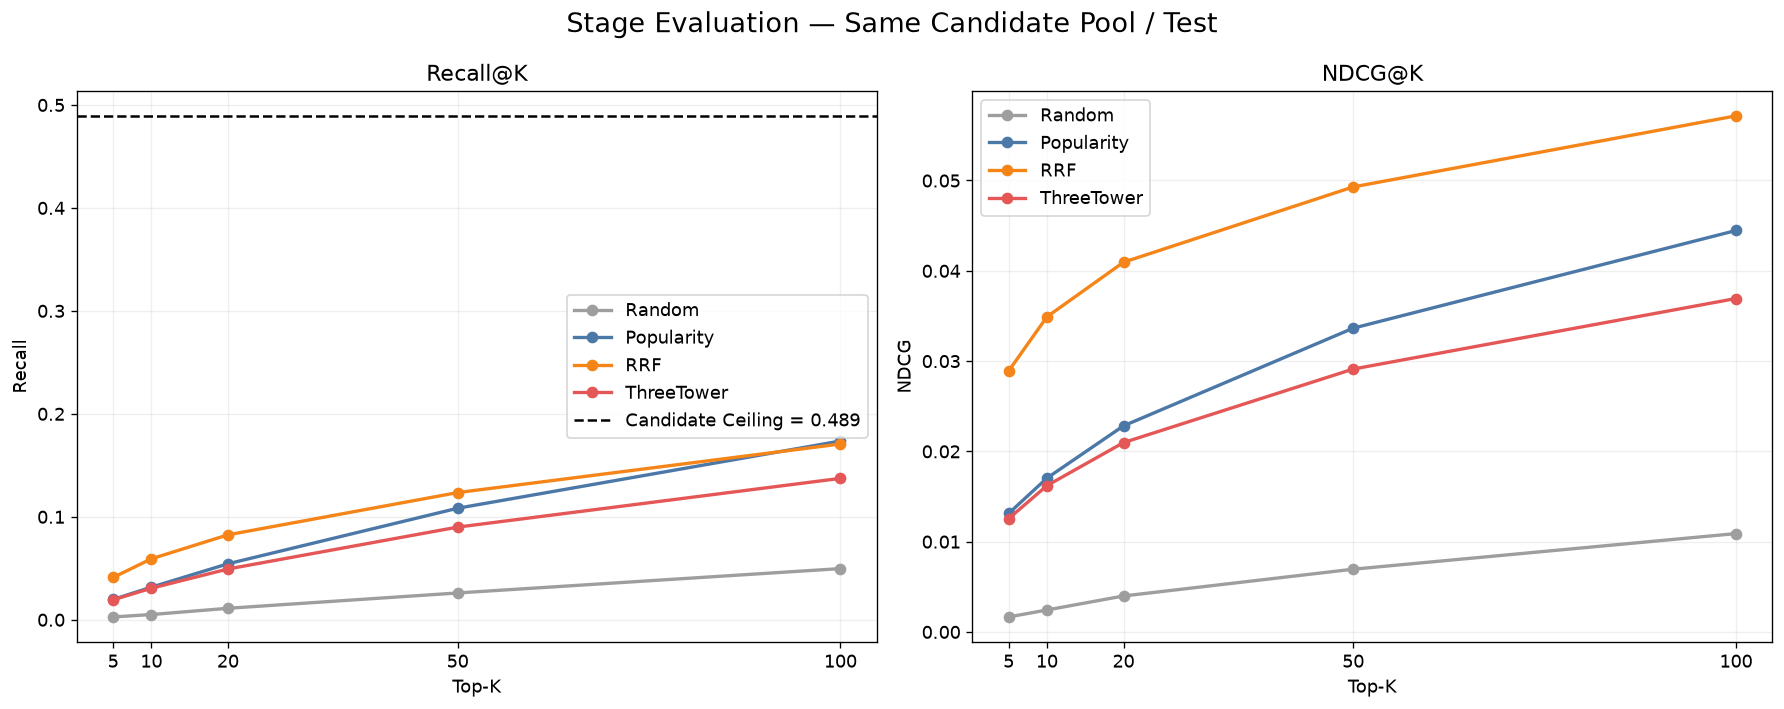

Saved: 16_stage_recall_ndcg_comparison.png


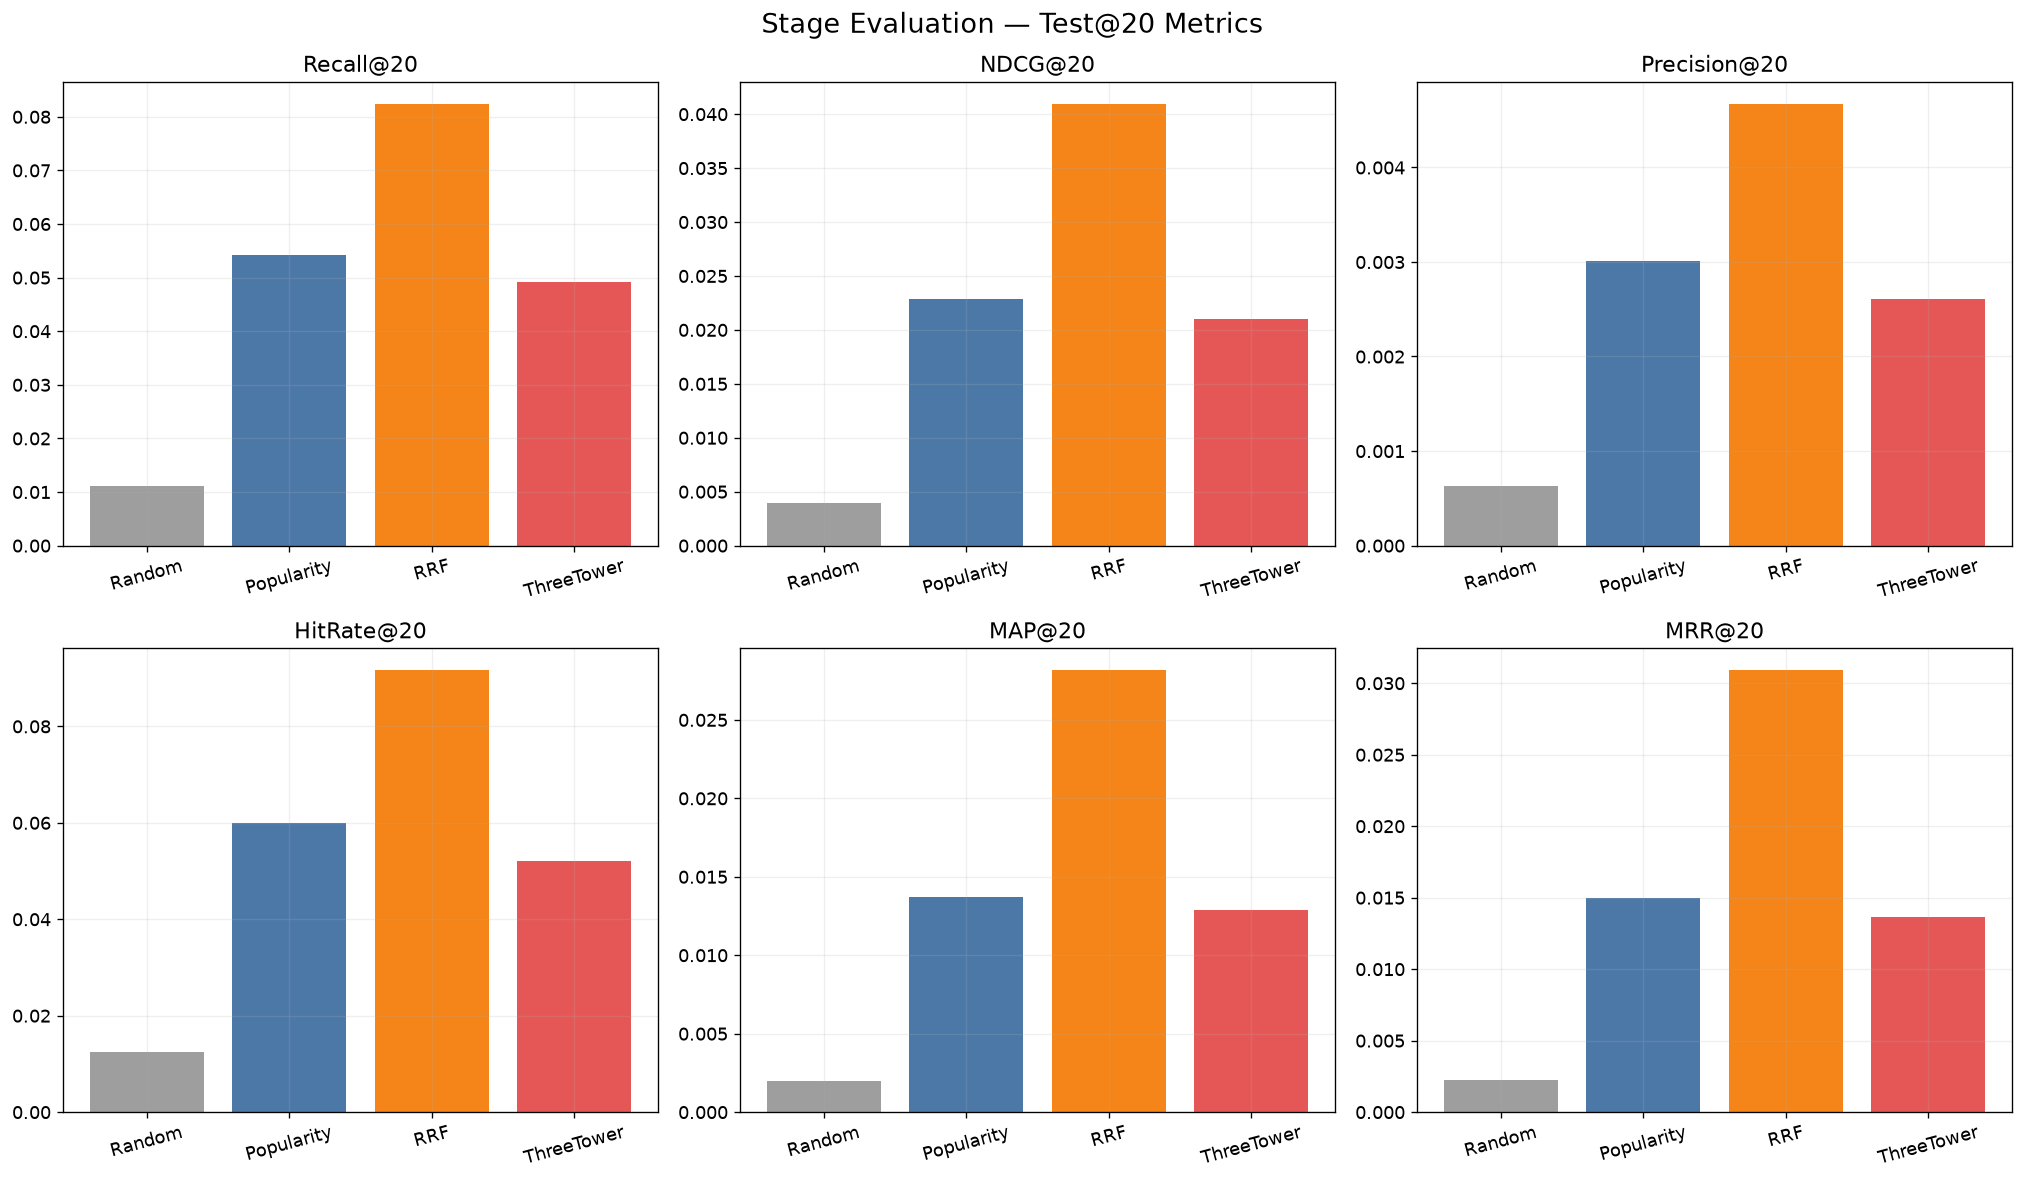

Saved: 17_stage_all_metrics_test20.png


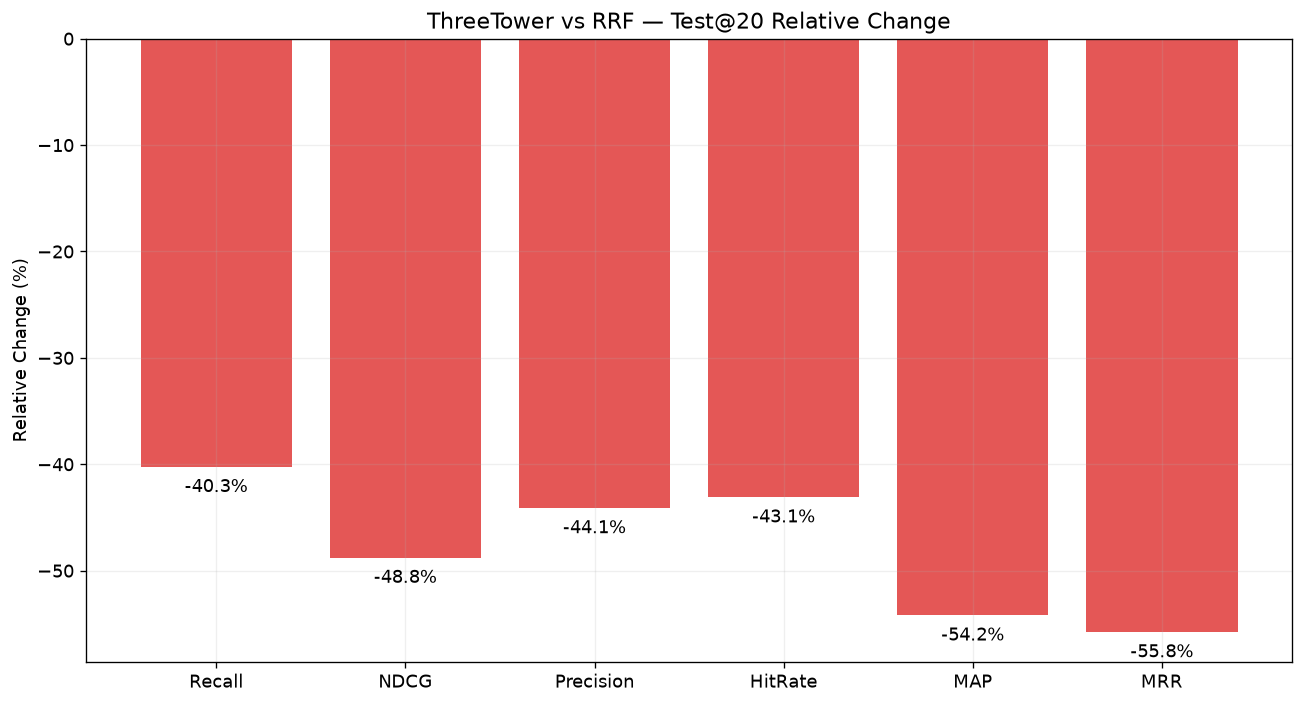

Saved: 18_threetower_vs_rrf_lift.png

=== ThreeTower vs RRF / Test@20 ===


,Lift (%)
Recall,-40.27
NDCG,-48.80
Precision,-44.14
HitRate,-43.12
MAP,-54.22
MRR,-55.80


In [ ]:

# ============================================================
# Cell 5 — Stage-by-Stage Evaluation
# Same Candidates: Random / Popularity / RRF / ThreeTower
# 依赖 Cell 1、Cell 3、Cell 4
# ============================================================

from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 333
rng = np.random.default_rng(SEED)

# ------------------------------------------------------------
# 1. 读取交互数据和真实标签
# ------------------------------------------------------------

matches = list(PROJECT_ROOT.rglob("baby.inter"))
assert matches, "未找到 baby.inter，请将数据放入项目 data 目录。"

INTER = pd.read_csv(matches[0], sep="\t")
INTER.columns = INTER.columns.str.strip()

required = {"userID", "itemID", "x_label"}
assert required.issubset(INTER.columns), (
    f"baby.inter 缺少字段：{required - set(INTER.columns)}"
)

TRAIN = INTER[INTER["x_label"] == 0].copy()
VALID = INTER[INTER["x_label"] == 1].copy()
TEST = INTER[INTER["x_label"] == 2].copy()

TRAIN["userID"] = TRAIN["userID"].astype(int)
TRAIN["itemID"] = TRAIN["itemID"].astype(int)

TEST_TRUTH = {
    int(u): set(g["itemID"].astype(int))
    for u, g in TEST.groupby("userID")
}

TEST_USERS = sorted(TEST_TRUTH)

TRAIN_SEEN_PAIRS = (
    TRAIN[["userID", "itemID"]]
    .drop_duplicates()
    .assign(_seen=1)
)

TRAIN_POP = TRAIN.groupby("itemID").size()

print("Train:", len(TRAIN))
print("Validation:", len(VALID))
print("Test:", len(TEST))
print("Test users:", len(TEST_USERS))


# ------------------------------------------------------------
# 2. 建立统一候选集
# 与 ThreeTower 的 Online Evaluation 一致：
# 32 组召回结果取并集，去重并过滤训练历史
# ------------------------------------------------------------

CANDIDATES = (
    RECALL_CANDIDATES[["userID", "itemID"]]
    .drop_duplicates()
    .merge(
        TRAIN_SEEN_PAIRS,
        on=["userID", "itemID"],
        how="left"
    )
)

CANDIDATES = (
    CANDIDATES[CANDIDATES["_seen"].isna()]
    [["userID", "itemID"]]
    .reset_index(drop=True)
)

CANDIDATE_PAIRS = pd.MultiIndex.from_frame(CANDIDATES)

CANDIDATE_DICT = {
    int(u): g["itemID"].astype(int).to_numpy()
    for u, g in CANDIDATES.groupby("userID")
}

print("\nUnique candidate pairs:", len(CANDIDATES))
print("Average candidates/user:",
      round(len(CANDIDATES) / CANDIDATES.userID.nunique(), 2))


# ------------------------------------------------------------
# 3. 读取 ThreeTower DCN2 的 Top-100 结果
# ------------------------------------------------------------

BEST_PRERANK = BEST_EXPERIMENT  # Cell 4 Validation 选出的配置

matching_files = [
    p for p in PRERANK_FILES
    if p.stem == BEST_PRERANK
]

assert matching_files, (
    f"找不到 {BEST_PRERANK}.parquet，请检查 prerank 文件夹。"
)

THREETOWER_DF = pd.read_parquet(matching_files[0])

assert {"userID", "itemID"}.issubset(THREETOWER_DF.columns)

THREETOWER_DF["userID"] = THREETOWER_DF["userID"].astype(int)
THREETOWER_DF["itemID"] = THREETOWER_DF["itemID"].astype(int)

# 检查 ThreeTower 输出是否属于统一候选集
tower_pairs = pd.MultiIndex.from_frame(
    THREETOWER_DF[["userID", "itemID"]]
)

outside_count = (~tower_pairs.isin(CANDIDATE_PAIRS)).sum()

print("ThreeTower candidates outside union:", outside_count)

assert outside_count == 0, (
    "ThreeTower 结果包含不属于当前候选集的商品，"
    "请检查召回 Parquet 是否与粗排训练时使用的版本一致。"
)

if "rank" in THREETOWER_DF.columns:
    THREETOWER_DF = THREETOWER_DF.sort_values(
        ["userID", "rank", "itemID"]
    )
elif "score" in THREETOWER_DF.columns:
    THREETOWER_DF = THREETOWER_DF.sort_values(
        ["userID", "score", "itemID"],
        ascending=[True, False, True]
    )
else:
    raise ValueError("ThreeTower Parquet 缺少 rank 和 score。")

THREETOWER_RANKING = {
    int(u): g["itemID"].astype(int).tolist()
    for u, g in THREETOWER_DF.groupby("userID")
}


# ------------------------------------------------------------
# 4. Random Baseline
# 每个用户独立随机排序，固定随机种子
# ------------------------------------------------------------

RANDOM_RANKING = {}

for u in TEST_USERS:
    items = CANDIDATE_DICT.get(u, np.array([], dtype=int))
    RANDOM_RANKING[u] = rng.permutation(items).tolist()


# ------------------------------------------------------------
# 5. Popularity Baseline
# 使用 Train 交互频次，不使用 Validation/Test 标签
# ------------------------------------------------------------

POPULARITY_RANKING = {}

for u in TEST_USERS:
    items = CANDIDATE_DICT.get(u, np.array([], dtype=int))

    if len(items) == 0:
        POPULARITY_RANKING[u] = []
        continue

    popularity = TRAIN_POP.reindex(
        items, fill_value=0
    ).to_numpy()

    order = np.lexsort((items, -popularity))

    POPULARITY_RANKING[u] = items[order].tolist()


# ------------------------------------------------------------
# 6. RRF Baseline
# 使用 Cell 3 已计算的融合分数
# 注意：这是全部 32 个实验参与的 RRF
# ------------------------------------------------------------

RRF_SCORED = (
    RRF_RANKING[["userID", "itemID", "score"]]
    .merge(
        CANDIDATES,
        on=["userID", "itemID"],
        how="inner"
    )
    .sort_values(
        ["userID", "score", "itemID"],
        ascending=[True, False, True]
    )
)

RRF_DICT = {
    int(u): g["itemID"].astype(int).tolist()
    for u, g in RRF_SCORED.groupby("userID")
}

# ------------------------------------------------------------
# 7. 统一评估函数
# ------------------------------------------------------------

def evaluate_ranking(ranking, truth, ks=KS):
    rows = []
    users = sorted(truth)

    for k in ks:
        recalls, ndcgs, precisions = [], [], []
        hitrates, maps, mrrs = [], [], []

        for u in users:
            positives = truth[u]
            recs = ranking.get(u, [])[:k]

            hits = np.array(
                [int(i in positives) for i in recs],
                dtype=float
            )

            n_hits = hits.sum()

            recalls.append(n_hits / len(positives))
            precisions.append(n_hits / k)
            hitrates.append(float(n_hits > 0))

            positions = np.arange(1, len(hits) + 1)

            dcg = np.sum(
                hits / np.log2(positions + 1)
            )

            ideal_len = min(len(positives), k)
            idcg = np.sum(
                1 / np.log2(np.arange(2, ideal_len + 2))
            )

            ndcgs.append(dcg / idcg if idcg else 0)

            if len(hits):
                cumulative_hits = np.cumsum(hits)
                ap = np.sum(
                    cumulative_hits / positions * hits
                ) / min(len(positives), k)
            else:
                ap = 0

            maps.append(ap)

            hit_positions = np.flatnonzero(hits)

            mrrs.append(
                1 / (hit_positions[0] + 1)
                if len(hit_positions) else 0
            )

        rows.append({
            "K": k,
            "Recall": np.mean(recalls),
            "NDCG": np.mean(ndcgs),
            "Precision": np.mean(precisions),
            "HitRate": np.mean(hitrates),
            "MAP": np.mean(maps),
            "MRR": np.mean(mrrs)
        })

    return pd.DataFrame(rows)


RANKINGS = {
    "Random": RANDOM_RANKING,
    "Popularity": POPULARITY_RANKING,
    "RRF": RRF_DICT,
    "ThreeTower": THREETOWER_RANKING
}

evaluation_frames = []

for method, ranking in RANKINGS.items():
    result = evaluate_ranking(ranking, TEST_TRUTH)
    result.insert(0, "Method", method)
    evaluation_frames.append(result)

STAGE_METRICS = pd.concat(
    evaluation_frames,
    ignore_index=True
)

STAGE_METRICS.to_csv(
    OUTPUT_DIR / "stage_comparison_test_metrics.csv",
    index=False
)

print("\n=== Same-Candidate Evaluation / Test@20 ===")
display(
    STAGE_METRICS[STAGE_METRICS.K == 20]
    .round(6)
)


# ------------------------------------------------------------
# 8. 计算候选集 Recall Ceiling
# 这是整个候选并集的理论召回上限，不是 Top-K 指标
# ------------------------------------------------------------

CANDIDATE_SETS = {
    u: set(items)
    for u, items in CANDIDATE_DICT.items()
}

CEILING = np.mean([
    len(positives & CANDIDATE_SETS.get(u, set()))
    / len(positives)
    for u, positives in TEST_TRUTH.items()
])

print(f"\nCandidate Recall Ceiling: {CEILING:.6f}")


# ------------------------------------------------------------
# 9. 图一：不同排序方法的 Recall@K / NDCG@K
# ------------------------------------------------------------

STAGE_COLORS = {
    "Random": "#9E9E9E",
    "Popularity": "#4C78A8",
    "RRF": "#F58518",
    "ThreeTower": "#E45756"
}

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, metric in zip(axes, ["Recall", "NDCG"]):

    for method in RANKINGS:
        sub = STAGE_METRICS[
            STAGE_METRICS.Method == method
        ].sort_values("K")

        ax.plot(
            sub.K,
            sub[metric],
            marker="o",
            linewidth=2,
            markersize=6,
            color=STAGE_COLORS[method],
            label=method
        )

    if metric == "Recall":
        ax.axhline(
            CEILING,
            color="black",
            linestyle="--",
            linewidth=1.5,
            label=f"Candidate Ceiling = {CEILING:.3f}"
        )

    ax.set_title(f"{metric}@K")
    ax.set_xlabel("Top-K")
    ax.set_ylabel(metric)
    ax.set_xticks(KS)
    ax.legend()

fig.suptitle(
    "Stage Evaluation — Same Candidate Pool / Test",
    fontsize=16
)

save_figure("16_stage_recall_ndcg_comparison.png")


# ------------------------------------------------------------
# 10. 图二：Test@20 六项指标综合对比
# ------------------------------------------------------------

METRICS_TO_PLOT = [
    "Recall", "NDCG", "Precision",
    "HitRate", "MAP", "MRR"
]

fig, axes = plt.subplots(2, 3, figsize=(17, 10))

test20 = STAGE_METRICS[
    STAGE_METRICS.K == 20
].set_index("Method")

for ax, metric in zip(axes.ravel(), METRICS_TO_PLOT):
    values = test20.loc[list(RANKINGS), metric]

    ax.bar(
        values.index,
        values.values,
        color=[STAGE_COLORS[m] for m in values.index]
    )

    ax.set_title(f"{metric}@20")
    ax.tick_params(axis="x", rotation=15)
    ax.set_ylim(bottom=0)

fig.suptitle(
    "Stage Evaluation — Test@20 Metrics",
    fontsize=16
)

save_figure("17_stage_all_metrics_test20.png")


# ------------------------------------------------------------
# 11. 图三：ThreeTower 相对 RRF 的指标变化
# ------------------------------------------------------------

rrf20 = test20.loc["RRF"]
tower20 = test20.loc["ThreeTower"]

lift = {}

for metric in METRICS_TO_PLOT:
    base = float(rrf20[metric])
    current = float(tower20[metric])

    lift[metric] = (
        (current - base) / base * 100
        if base != 0 else np.nan
    )

LIFT_VS_RRF = pd.Series(lift, name="Lift (%)")

fig, ax = plt.subplots(figsize=(11, 6))

values = LIFT_VS_RRF.values

ax.bar(
    LIFT_VS_RRF.index,
    values,
    color=[
        "#54A24B" if v >= 0 else "#E45756"
        for v in values
    ]
)

ax.axhline(0, color="black", linewidth=1)
ax.set_ylabel("Relative Change (%)")
ax.set_title("ThreeTower vs RRF — Test@20 Relative Change")

for i, value in enumerate(values):
    ax.annotate(
        f"{value:+.1f}%",
        (i, value),
        xytext=(0, 5 if value >= 0 else -15),
        textcoords="offset points",
        ha="center"
    )

save_figure("18_threetower_vs_rrf_lift.png")

print("\n=== ThreeTower vs RRF / Test@20 ===")
display(LIFT_VS_RRF.to_frame().round(2))


# ------------------------------------------------------------
# 12. 图四：全部指标随 K 的变化
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, metric in zip(axes.ravel(), METRICS_TO_PLOT):

    for method in RANKINGS:
        sub = STAGE_METRICS[
            STAGE_METRICS.Method == method
        ].sort_values("K")

        ax.plot(
            sub.K,
            sub[metric],
            marker="o",
            linewidth=2,
            label=method,
            color=STAGE_COLORS[method]
        )

    ax.set_title(metric)
    ax.set_xlabel("Top-K")
    ax.set_xticks(KS)

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles, labels,
    loc="lower center",
    ncol=4,
    bbox_to_anchor=(0.5, -0.01)
)

fig.suptitle(
    "Stage Evaluation — All Test Metrics by K",
    fontsize=16
)

fig.subplots_adjust(bottom=0.1)

save_figure("19_stage_all_metrics_by_k.png")


# ------------------------------------------------------------
# 13. 汇总与保存
# ------------------------------------------------------------

summary = test20[
    METRICS_TO_PLOT
].copy()

summary["CandidateRecallCeiling"] = CEILING

summary.to_csv(
    OUTPUT_DIR / "stage_comparison_summary.csv"
)

print("\n=== Final Stage Comparison ===")
display(summary.round(6))

print("\nAll four analysis modules completed.")
print("Results saved to:", OUTPUT_DIR)
